# Classification de la qualité du vin

Projet 2 de Machine Learning 1, EFREI 2026-2027.

Ce notebook contient le code complet du projet. Il réunit les trois parties dans l'ordre, chacune répondant à une question. Les données d'origine sont dans le dossier `data`. Chaque partie enregistre ce dont la suivante a besoin, le notebook se lance donc de haut en bas.

## Sommaire

**[Partie 1. Préparer des données fiables](#Partie-1.-Préparer-des-données-fiables)**

[1.1 Que contiennent les données ?](#1.1-Que-contiennent-les-données-?)  
[1.2 Manque-t-il des valeurs ?](#1.2-Manque-t-il-des-valeurs-?)  
[1.3 Qu'est-ce qu'un bon vin, et pourquoi l'accuracy ne suffit-elle pas ?](#1.3-Qu'est-ce-qu'un-bon-vin,-et-pourquoi-l'accuracy-ne-suffit-elle-pas-?)  
[1.4 Quels vins garde-t-on pour le test final ?](#1.4-Quels-vins-garde-t-on-pour-le-test-final-?)  
[1.5 Qu'est-ce qui distingue un bon vin ?](#1.5-Qu'est-ce-qui-distingue-un-bon-vin-?)  
[1.6 Des mesures disent-elles la même chose ?](#1.6-Des-mesures-disent-elles-la-même-chose-?)  
[1.7 Comment vérifier nos choix sans toucher au test ?](#1.7-Comment-vérifier-nos-choix-sans-toucher-au-test-?)  
[1.8 Faut-il supprimer les doublons ?](#1.8-Faut-il-supprimer-les-doublons-?)  
[1.9 Faut-il retirer les valeurs extrêmes ?](#1.9-Faut-il-retirer-les-valeurs-extrêmes-?)  
[1.10 Faut-il mettre les mesures à la même échelle ?](#1.10-Faut-il-mettre-les-mesures-à-la-même-échelle-?)  
[1.11 Faut-il retirer des mesures ?](#1.11-Faut-il-retirer-des-mesures-?)  

**[Partie 2. Construire, régler et comprendre les cinq modèles](#Partie-2.-Construire,-régler-et-comprendre-les-cinq-modèles)**

[2.1 Quels sont les cinq modèles, et lesquels sont linéaires ?](#2.1-Quels-sont-les-cinq-modèles,-et-lesquels-sont-linéaires-?)  
[2.2 Que donnent-ils sans réglage ?](#2.2-Que-donnent-ils-sans-réglage-?)  
[2.3 Comment choisir les hyperparamètres ?](#2.3-Comment-choisir-les-hyperparamètres-?)  
[2.4 Pourquoi régler avec l'AUC plutôt qu'avec le F1 ?](#2.4-Pourquoi-régler-avec-l'AUC-plutôt-qu'avec-le-F1-?)  
[2.5 La recherche aléatoire fait-elle aussi bien ?](#2.5-La-recherche-aléatoire-fait-elle-aussi-bien-?)  
[2.6 Comment éviter un modèle trop rigide ou trop collé aux données ?](#2.6-Comment-éviter-un-modèle-trop-rigide-ou-trop-collé-aux-données-?)  
[2.7 Qu'a appris chaque modèle ?](#2.7-Qu'a-appris-chaque-modèle-?)  
[2.8 Combiner les modèles aide-t-il ?](#2.8-Combiner-les-modèles-aide-t-il-?)  

**[Partie 3. Choisir le modèle et juger sa fiabilité](#Partie-3.-Choisir-le-modèle-et-juger-sa-fiabilité)**

[3.1 Quel modèle est le meilleur, et sur quoi se base-t-on ?](#3.1-Quel-modèle-est-le-meilleur,-et-sur-quoi-se-base-t-on-?)  
[3.2 Que donne le modèle, et à partir de quelle probabilité dit-on « bon » ?](#3.2-Que-donne-le-modèle,-et-à-partir-de-quelle-probabilité-dit-on-«-bon-»-?)  
[3.3 Que vaut-il sur des vins qu'il n'a jamais vus ?](#3.3-Que-vaut-il-sur-des-vins-qu'il-n'a-jamais-vus-?)  
[3.4 Est-il aussi bon sur les rouges que sur les blancs ?](#3.4-Est-il-aussi-bon-sur-les-rouges-que-sur-les-blancs-?)  
[3.5 Où se trompe-t-il, et pourquoi ?](#3.5-Où-se-trompe-t-il,-et-pourquoi-?)  
[3.6 Quel seuil pour quel usage ?](#3.6-Quel-seuil-pour-quel-usage-?)  
[3.7 Quelles sont les limites ?](#3.7-Quelles-sont-les-limites-?)  
[3.8 Que retenir de tout le projet ?](#3.8-Que-retenir-de-tout-le-projet-?)  


# Partie 1. Préparer des données fiables

Projet 2 de Machine Learning 1, EFREI 2026-2027.

Nous voulons prédire si un vin est bon à partir de 11 mesures de laboratoire et de sa couleur. Cette première partie nettoie les données, les explore et vérifie chaque choix de préparation par une expérience. Elle enregistre à la fin un jeu d'entraînement et un jeu de test que les parties 2 et 3 réutilisent.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Style commun des graphiques du groupe
ENCRE, PRUNE, MIEL, BRUME = "#1F2A44", "#7A3B69", "#E3A72F", "#C5CAD3"
plt.rcParams.update({
    "font.family": "serif", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#EAEAEA", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 12,
    "legend.frameon": False,
})
GRAINE = 42
pd.set_option("display.precision", 3)

## 1.1 Que contiennent les données ?

Les données décrivent 6 497 vins portugais par 11 mesures de laboratoire, une couleur et une note de dégustation sur 10. Elles arrivent en deux fichiers, un pour les rouges et un pour les blancs. Nous les réunissons en gardant la couleur dans une colonne `type`.

In [2]:
rouge = pd.read_csv("data/winequality-red.csv", sep=";")
blanc = pd.read_csv("data/winequality-white.csv", sep=";")
rouge["type"] = "rouge"
blanc["type"] = "blanc"

vins_brut = pd.concat([rouge, blanc], ignore_index=True)
print("Vins rouges", len(rouge), "| vins blancs", len(blanc), "| total", len(vins_brut))
vins_brut.describe().T[["mean", "std", "min", "50%", "max"]]

Vins rouges 1599 | vins blancs 4898 | total 6497


,mean,std,min,50%,max
fixed acidity,7.215,1.296,3.800,7.000,15.900
volatile acidity,0.340,0.165,0.080,0.290,1.580
citric acid,0.319,0.145,0.000,0.310,1.660
residual sugar,5.443,4.758,0.600,3.000,65.800
chlorides,0.056,0.035,0.009,0.047,0.611
free sulfur dioxide,30.525,17.749,1.000,29.000,289.000
total sulfur dioxide,115.745,56.522,6.000,118.000,440.000
density,0.995,0.003,0.987,0.995,1.039
pH,3.219,0.161,2.720,3.210,4.010
sulphates,0.531,0.149,0.220,0.510,2.000


Les mesures n'ont pas du tout la même échelle. Le dioxyde de soufre total monte jusqu'à 440 alors que la densité varie de quelques centièmes. Certains maximums sont aussi très loin de la médiane, par exemple 65,8 grammes de sucre pour une médiane de 3. Ces deux remarques sont reprises en 1.9 et en 1.10.

## 1.2 Manque-t-il des valeurs ?

Non, le tableau ne contient aucune valeur manquante, il n'y a donc rien à compléter. En revanche, beaucoup de lignes sont présentes en plusieurs exemplaires.

In [3]:
print("Valeurs manquantes dans tout le tableau", vins_brut.isna().sum().sum())
print("Lignes identiques à une autre ligne", vins_brut.duplicated().sum(),
      f"soit {vins_brut.duplicated().mean():.1%} du tableau")

Valeurs manquantes dans tout le tableau 0
Lignes identiques à une autre ligne 1177 soit 18.1% du tableau


1177 lignes sont la copie exacte d'une autre ligne. Nous les retirons dès maintenant pour ne garder qu'un exemplaire de chaque vin. La section 1.8 explique ce choix et le prouve par une expérience.

## 1.3 Qu'est-ce qu'un bon vin, et pourquoi l'accuracy ne suffit-elle pas ?

Un bon vin est un vin noté au moins 7 sur 10, et comme ces vins sont rares, compter simplement les bonnes réponses ne suffit pas à juger un modèle. Nous créons la cible `bon`, qui vaut 1 pour ces vins et 0 pour les autres. Nous transformons aussi la couleur en une colonne `est_rouge` qui vaut 1 ou 0. Une seule colonne suffit puisqu'il n'y a que deux couleurs.

In [4]:
vins = vins_brut.drop_duplicates().reset_index(drop=True)
vins["est_rouge"] = (vins["type"] == "rouge").astype(int)
vins["bon"] = (vins["quality"] >= 7).astype(int)

numeriques = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
              "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]
variables = numeriques + ["est_rouge"]

print("Vins distincts", len(vins), "| bons vins", vins["bon"].sum(), f"({vins['bon'].mean():.1%})")
vins.groupby("type")["bon"].agg(nombre="size", part_de_bons="mean").round(3)

Vins distincts 5320 | bons vins 1009 (19.0%)


,nombre,part_de_bons
type,,
blanc,3961,0.208
rouge,1359,0.135


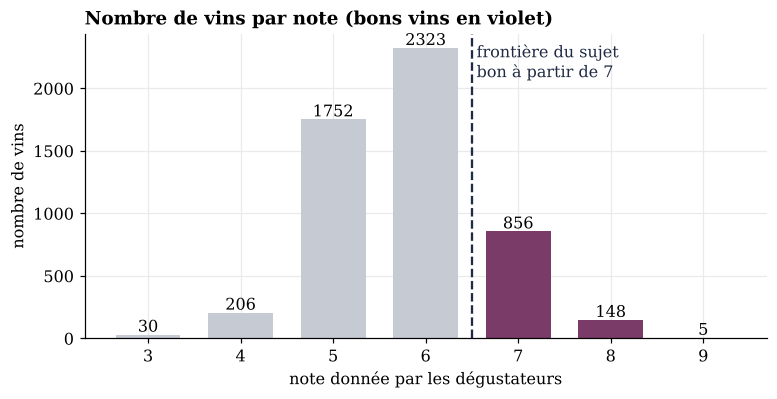

In [5]:
notes = vins["quality"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(notes.index, notes.values, color=[PRUNE if n >= 7 else BRUME for n in notes.index], width=0.7)
for note, nombre in notes.items():
    ax.text(note, nombre + 25, str(nombre), ha="center")
ax.axvline(6.5, color=ENCRE, linestyle="--")
ax.text(6.55, notes.max() * 0.9, "frontière du sujet\nbon à partir de 7", color=ENCRE)
ax.set_xlabel("note donnée par les dégustateurs"); ax.set_ylabel("nombre de vins")
ax.set_title("Nombre de vins par note (bons vins en violet)")
plt.show()

Il reste 5320 vins distincts et 19% d'entre eux sont bons. Il y a donc environ un bon vin pour quatre mauvais. La frontière passe entre les notes 6 et 7, qui font partie des notes les plus fréquentes.

L'accuracy est la part de bonnes réponses sur tous les vins. Ici elle est trompeuse. Un modèle qui répondrait toujours mauvais aurait 81% d'accuracy sans trouver un seul bon vin. Nous utilisons donc quatre autres mesures dans tout le projet.

| Mesure | Ce qu'elle dit |
|---|---|
| Rappel | Sur 100 bons vins, combien le modèle en retrouve |
| Précision | Sur 100 vins que le modèle annonce bons, combien le sont vraiment |
| F1-score | Une seule note qui n'est élevée que si le rappel et la précision le sont tous les deux |
| AUC | La chance que le modèle donne une meilleure note à un bon vin qu'à un mauvais, quand on en tire un de chaque au hasard. Elle vaut 0,5 pour un modèle qui répond au hasard et 1 pour un classement parfait |

## 1.4 Quels vins garde-t-on pour le test final ?

Nous mettons de côté 20 % des vins et nous n'y touchons plus jusqu'à la partie 3. Ce jeu de test sert à mesurer le modèle final sur des vins qu'il n'a jamais vus. Si nous l'utilisions pour explorer ou pour régler les modèles, ce score final serait trop optimiste.

Le tirage est stratifié, ce qui veut dire qu'il respecte certaines proportions des deux côtés. Nous lui imposons de garder la même part de bons vins et la même part de rouges. Les bons vins rouges sont rares, il n'y en a que 184 dans tout le fichier. Avec un tirage libre, le test pourrait en recevoir trop ou trop peu par malchance.

In [6]:
# Quatre groupes à respecter des deux côtés, blanc mauvais, blanc bon, rouge mauvais, rouge bon
groupe = vins["type"] + "_" + vins["bon"].astype(str)

train, test = train_test_split(vins, test_size=0.2, stratify=groupe, random_state=GRAINE)
X_train, y_train = train[variables], train["bon"]

controle = pd.DataFrame({
    "nombre de vins": [len(train), len(test)],
    "part de bons vins": [train["bon"].mean(), test["bon"].mean()],
    "part de rouges": [train["est_rouge"].mean(), test["est_rouge"].mean()],
    "part de bons parmi les rouges": [train[train["est_rouge"] == 1]["bon"].mean(), test[test["est_rouge"] == 1]["bon"].mean()],
}, index=["entraînement", "test"])
controle.round(3)

,nombre de vins,part de bons vins,part de rouges,part de bons parmi les rouges
entraînement,4256,0.19,0.255,0.135
test,1064,0.19,0.256,0.136


Les deux jeux ont bien la même part de bons vins, la même part de rouges et la même part de bons vins parmi les rouges. Toute la suite de cette partie n'utilise que le jeu d'entraînement.

## 1.5 Qu'est-ce qui distingue un bon vin ?

C'est surtout le degré d'alcool, et dans une moindre mesure une faible acidité volatile. Nous calculons la corrélation de chaque mesure avec la cible, une fois chez les rouges et une fois chez les blancs.

,rouges,blancs
free sulfur dioxide,-0.08,-0.03
pH,-0.06,0.11
residual sugar,0.06,-0.14
fixed acidity,0.14,-0.09
total sulfur dioxide,-0.14,-0.18
chlorides,-0.10,-0.19
citric acid,0.20,-0.03
sulphates,0.22,0.02
volatile acidity,-0.26,-0.05
density,-0.12,-0.31


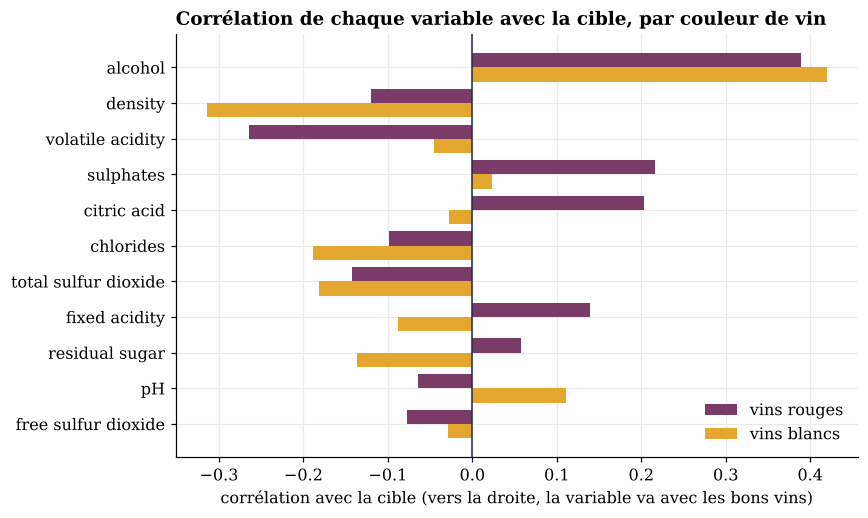

In [7]:
# Corrélation de chaque variable avec la cible, calculée séparément pour les rouges et pour les blancs
rouges, blancs = train[train["type"] == "rouge"], train[train["type"] == "blanc"]
corr_couleur = pd.DataFrame({"rouges": rouges[numeriques].corrwith(rouges["bon"]),
                             "blancs": blancs[numeriques].corrwith(blancs["bon"])})
corr_couleur = corr_couleur.loc[corr_couleur.abs().max(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(corr_couleur))
ax.barh(positions + 0.2, corr_couleur["rouges"], height=0.4, color=PRUNE, label="vins rouges")
ax.barh(positions - 0.2, corr_couleur["blancs"], height=0.4, color=MIEL, label="vins blancs")
ax.axvline(0, color=ENCRE, linewidth=1)
ax.set_yticks(positions); ax.set_yticklabels(corr_couleur.index)
ax.set_xlabel("corrélation avec la cible (vers la droite, la variable va avec les bons vins)")
ax.set_title("Corrélation de chaque variable avec la cible, par couleur de vin")
ax.legend(loc="lower right")
plt.show()
corr_couleur.round(2)

Une barre vers la droite signifie que la mesure est plus élevée chez les bons vins. Une barre vers la gauche signifie l'inverse. Plus la barre est longue, plus le lien est fort.

L'alcool a les deux barres les plus longues, et elles sont presque égales (+0.39 pour les rouges et +0.42 pour les blancs). Pour d'autres mesures, les deux couleurs ne se ressemblent pas. L'acidité volatile, qui donne un goût de vinaigre, pénalise les rouges (-0.26) et presque pas les blancs (-0.05). Nous nous sommes demandé si cette différence entre couleurs gênait certains modèles. La partie 2 teste cette idée en 2.7.

Asymétrie de chaque variable (0 pour une loi normale)
chlorides               4.9
residual sugar          1.8
sulphates               1.8
fixed acidity           1.7
volatile acidity        1.5
free sulfur dioxide     1.5
density                 0.8
citric acid             0.5
alcohol                 0.5
pH                      0.4
total sulfur dioxide    0.1


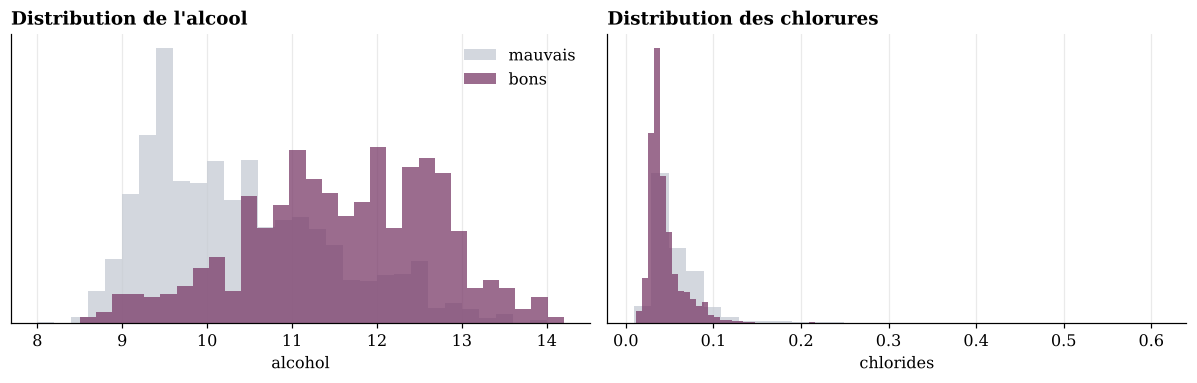

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, variable in zip(axes, ["alcohol", "chlorides"]):
    for classe, couleur, nom in [(0, BRUME, "mauvais"), (1, PRUNE, "bons")]:
        ax.hist(train[train["bon"] == classe][variable], bins=30, density=True, color=couleur, alpha=0.75, label=nom)
    ax.set_xlabel(variable); ax.set_yticks([])
axes[0].set_title("Distribution de l'alcool")
axes[1].set_title("Distribution des chlorures")
axes[0].legend()
plt.tight_layout(); plt.show()

print("Asymétrie de chaque variable (0 pour une loi normale)")
print(train[numeriques].skew().round(1).sort_values(ascending=False).to_string())

Même pour l'alcool, les bons et les mauvais vins se recouvrent largement. Aucune mesure ne suffit seule, et aucun modèle n'atteindra un score parfait. On voit aussi que les chlorures ont une distribution très étalée vers la droite, loin de la forme en cloche d'une loi normale.

## 1.6 Des mesures disent-elles la même chose ?

Oui, plusieurs mesures se répètent, en particulier la densité qui dépend presque entièrement des autres.

Les 11 autres variables permettent de recalculer la densité à 95%.


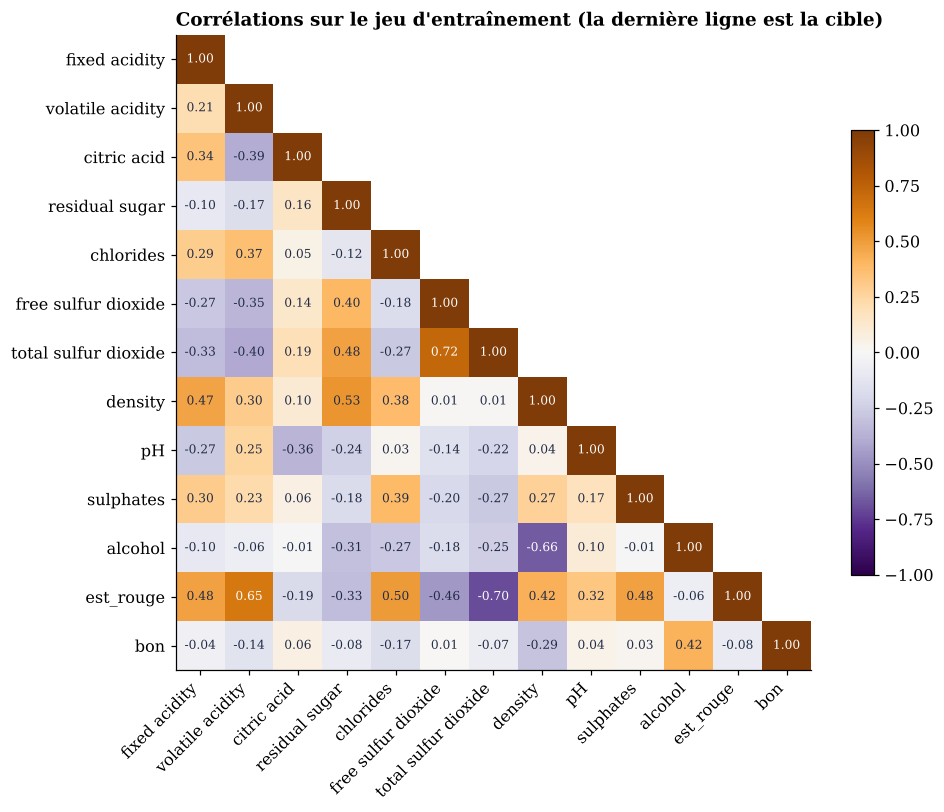

In [9]:
colonnes = numeriques + ["est_rouge", "bon"]
correlations = train[colonnes].corr()
triangle = correlations.where(np.tril(np.ones(correlations.shape, dtype=bool)))

fig, ax = plt.subplots(figsize=(9.5, 7.5))
image = ax.imshow(triangle, cmap="PuOr_r", vmin=-1, vmax=1)
for i in range(len(colonnes)):
    for j in range(i + 1):
        valeur = correlations.iloc[i, j]
        ax.text(j, i, f"{valeur:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(valeur) > 0.6 else ENCRE)
ax.set_xticks(range(len(colonnes))); ax.set_xticklabels(colonnes, rotation=45, ha="right")
ax.set_yticks(range(len(colonnes))); ax.set_yticklabels(colonnes)
ax.grid(False); fig.colorbar(image, shrink=0.7)
ax.set_title("Corrélations sur le jeu d'entraînement (la dernière ligne est la cible)")
plt.show()

autres = [v for v in variables if v != "density"]
r2_densite = LinearRegression().fit(train[autres], train["density"]).score(train[autres], train["density"])
print(f"Les 11 autres variables permettent de recalculer la densité à {r2_densite:.0%}.")

La densité est fortement liée à l'alcool (-0.66), et les deux mesures de dioxyde de soufre vont ensemble (+0.72). La densité se recalcule même à 95% à partir des autres mesures. C'est physique, l'alcool est plus léger que l'eau et le sucre plus lourd.

Cette répétition aura des conséquences pour deux modèles de la partie 2. Naive Bayes suppose que les mesures sont indépendantes, et les poids de la régression logistique deviennent difficiles à lire quand deux mesures portent la même information.

## 1.7 Comment vérifier nos choix sans toucher au test ?

Nous utilisons la validation croisée, qui permet de noter un modèle sur des vins qu'il n'a pas vus en n'utilisant que le jeu d'entraînement. Les vins d'entraînement sont coupés en 5 groupes. Le modèle apprend sur 4 groupes et il est noté sur le cinquième. On recommence 5 fois en changeant le groupe mis de côté, puis on fait la moyenne des 5 notes.

Cette méthode sert dans tout le projet. Elle sert ici à tester les choix de préparation, puis en partie 2 à régler les modèles et en partie 3 à choisir le modèle final et son seuil.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)

def notes_cv(modele, X, y, decoupage=cv, groupes=None):
    """AUC et F1-score moyens en validation croisée à 5 plis."""
    notes = cross_validate(modele, X, y, cv=decoupage, groups=groupes, scoring=["roc_auc", "f1"])
    return notes["test_roc_auc"].mean(), notes["test_f1"].mean()

temoins = {
    "Régression logistique": Pipeline([("echelle", StandardScaler()), ("modele", LogisticRegression(max_iter=1000))]),
    "k plus proches voisins": Pipeline([("echelle", StandardScaler()), ("modele", KNeighborsClassifier(15, weights="distance"))]),
    "Arbre de décision": DecisionTreeClassifier(random_state=GRAINE),
    "Forêt aléatoire": RandomForestClassifier(200, random_state=GRAINE, n_jobs=-1),
}

# Quatre modèles simples pour les expériences sur la mise à l'échelle et les valeurs extrêmes
candidats = {
    "Régression logistique": LogisticRegression(max_iter=5000),
    "k plus proches voisins": KNeighborsClassifier(15),
    "Arbre de décision": DecisionTreeClassifier(max_depth=4, random_state=GRAINE),
    "Naive Bayes": GaussianNB(),
}

## 1.8 Faut-il supprimer les doublons ?

Oui, car ils permettent au modèle de reconnaître des vins déjà vus, ce qui gonfle les scores sans que le modèle soit meilleur. Pour le montrer, nous comparons trois situations sur les données complètes. Dans la première, les doublons sont gardés. Dans la deuxième, ils sont gardés mais les copies d'un même vin restent toujours dans le même groupe de la validation croisée. Dans la troisième, ils sont supprimés.

,AUC doublons mélangés,AUC doublons jamais séparés,AUC doublons supprimés,F1 doublons mélangés,F1 doublons supprimés
modèle,,,,,
Régression logistique,0.810,0.811,0.825,0.364,0.370
k plus proches voisins,0.911,0.831,0.837,0.673,0.468
Arbre de décision,0.752,0.655,0.649,0.598,0.428
Forêt aléatoire,0.923,0.853,0.850,0.665,0.459


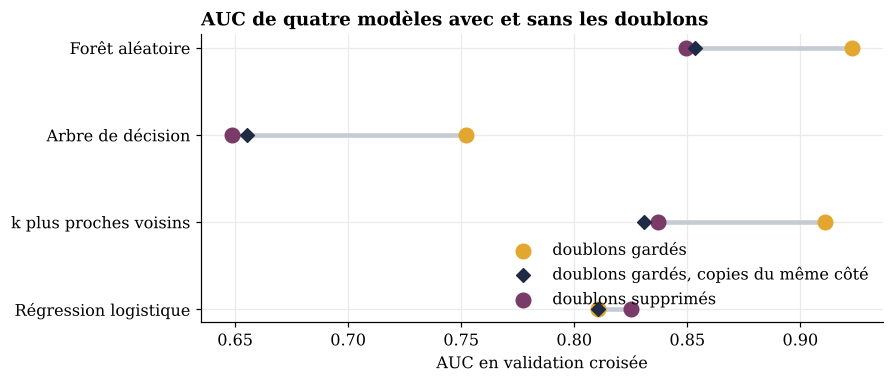

In [11]:
X_brut = vins_brut.assign(est_rouge=(vins_brut["type"] == "rouge").astype(int))[variables]
y_brut = (vins_brut["quality"] >= 7).astype(int)
numero_du_vin = X_brut.groupby(variables).ngroup()      # deux lignes identiques portent le même numéro
cv_groupe = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=GRAINE)

lignes = []
for nom, modele in temoins.items():
    auc_a, f1_a = notes_cv(modele, X_brut, y_brut)
    auc_b, f1_b = notes_cv(modele, X_brut, y_brut, cv_groupe, numero_du_vin)
    auc_c, f1_c = notes_cv(modele, X_train, y_train)
    lignes.append({"modèle": nom, "AUC doublons mélangés": auc_a, "AUC doublons jamais séparés": auc_b,
                   "AUC doublons supprimés": auc_c, "F1 doublons mélangés": f1_a, "F1 doublons supprimés": f1_c})
exp_doublons = pd.DataFrame(lignes).set_index("modèle")

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(len(exp_doublons))
ax.hlines(positions, exp_doublons["AUC doublons supprimés"], exp_doublons["AUC doublons mélangés"], color=BRUME, linewidth=3)
ax.scatter(exp_doublons["AUC doublons mélangés"], positions, color=MIEL, s=90, label="doublons gardés", zorder=3)
ax.scatter(exp_doublons["AUC doublons jamais séparés"], positions, color=ENCRE, s=40, marker="D", label="doublons gardés, copies du même côté", zorder=4)
ax.scatter(exp_doublons["AUC doublons supprimés"], positions, color=PRUNE, s=90, label="doublons supprimés", zorder=3)
ax.set_yticks(positions); ax.set_yticklabels(exp_doublons.index); ax.set_xlabel("AUC en validation croisée")
ax.set_title("AUC de quatre modèles avec et sans les doublons")
ax.legend(loc="lower right")
plt.show()
exp_doublons.round(3)

Avec les doublons, la forêt aléatoire obtient une AUC de 0.923. Sans eux, 0.850. Le F1-score des voisins passe de 0.67 à 0.47.

La deuxième situation donne la preuve. Les données sont exactement les mêmes que dans la première, on interdit seulement qu'un vin soit à la fois dans les groupes d'apprentissage et dans le groupe noté. Le score de la forêt retombe alors à 0.853. Tout le gain venait donc de copies que le modèle avait déjà vues. On appelle cela une fuite de données.

La régression logistique ne change presque pas. Elle trace une seule frontière et ne peut pas retenir un vin en particulier, contrairement aux voisins, à l'arbre et à la forêt.

Onze mesures identiques jusqu'à la dernière décimale avec la même note, cela ressemble plus à un échantillon saisi plusieurs fois qu'à des vins différents. Nos scores seront donc plus bas que ceux d'une analyse qui garde les doublons, mais ils disent ce que le modèle sait faire sur un vin vraiment nouveau.

## 1.9 Faut-il retirer les valeurs extrêmes ?

Non, car elles signalent souvent un vin raté et aident donc à reconnaître les mauvais vins. Nous repérons d'abord les valeurs extrêmes avec la règle de la boîte à moustaches.

In [12]:
def est_aberrante(serie):
    """Règle de la boîte à moustaches, au-delà de 1,5 fois l'écart interquartile."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    return (serie < q1 - 1.5 * (q3 - q1)) | (serie > q3 + 1.5 * (q3 - q1))

vin_atypique = train[numeriques].apply(est_aberrante).any(axis=1)
print(f"Vins avec au moins une valeur aberrante   {vin_atypique.sum()} soit {vin_atypique.mean():.0%}")
print(f"Part de bons vins parmi ces vins atypiques {train[vin_atypique]['bon'].mean():.0%}")
print(f"Part de bons vins parmi les autres         {train[~vin_atypique]['bon'].mean():.0%}")

Vins avec au moins une valeur aberrante   880 soit 21%
Part de bons vins parmi ces vins atypiques 12%
Part de bons vins parmi les autres         21%


Cette règle signale 21% des vins. Seulement 12% d'entre eux sont bons, contre 21% des autres. Une valeur extrême n'est donc pas une erreur de mesure. Elle correspond souvent à un défaut, comme trop d'acide acétique ou trop de sel.

Nous vérifions ensuite ce que donnerait leur suppression.

In [13]:
lignes = []
for nom, modele in candidats.items():
    modele = Pipeline([("echelle", StandardScaler()), ("modele", modele)])
    lignes.append({"modèle": nom,
                   "tous les vins": notes_cv(modele, X_train, y_train)[0],
                   "sans les vins atypiques": notes_cv(modele, X_train[~vin_atypique], y_train[~vin_atypique])[0]})
exp_aberrantes = pd.DataFrame(lignes).set_index("modèle")
print(f"Supprimer les vins atypiques ferait perdre {vin_atypique.mean():.0%} des vins d'entraînement.")
exp_aberrantes.round(3)

Supprimer les vins atypiques ferait perdre 21% des vins d'entraînement.


,tous les vins,sans les vins atypiques
modèle,,
Régression logistique,0.825,0.815
k plus proches voisins,0.827,0.811
Arbre de décision,0.801,0.778
Naive Bayes,0.769,0.763


Les quatre modèles sont moins bons quand on retire ces vins, et on perd un cinquième des données. Nous les gardons.

## 1.10 Faut-il mettre les mesures à la même échelle ?

Oui pour les modèles qui calculent des distances, et cela ne change rien pour les autres.

In [14]:
lignes = []
for nom, modele in candidats.items():
    lignes.append({"modèle": nom,
                   "sans mise à l'échelle": notes_cv(modele, X_train, y_train)[0],
                   "standardisation": notes_cv(Pipeline([("echelle", StandardScaler()), ("modele", modele)]), X_train, y_train)[0],
                   "normalisation min-max": notes_cv(Pipeline([("echelle", MinMaxScaler()), ("modele", modele)]), X_train, y_train)[0]})
exp_echelle = pd.DataFrame(lignes).set_index("modèle")
exp_echelle.round(3)

,sans mise à l'échelle,standardisation,normalisation min-max
modèle,,,
Régression logistique,0.820,0.825,0.820
k plus proches voisins,0.705,0.827,0.825
Arbre de décision,0.801,0.801,0.801
Naive Bayes,0.771,0.769,0.769


Le modèle des voisins passe de 0.705 à 0.827. Il cherche les vins les plus proches, et sans mise à l'échelle la distance est dominée par le dioxyde de soufre total, dont les valeurs sont les plus grandes. Le SVM de la partie 2 repose aussi sur des distances.

L'arbre de décision et Naive Bayes ne bougent pas. L'arbre compare chaque mesure à un seuil, et changer l'unité déplace le seuil sans changer la réponse. Naive Bayes calcule une moyenne et un écart type par mesure, il s'adapte donc tout seul.

La standardisation et la normalisation min-max donnent presque le même résultat. Nous retenons la standardisation, qui est moins sensible aux valeurs extrêmes que nous avons gardées. Avec le min-max, le vin à 65,8 grammes de sucre écraserait tous les autres vers zéro.

La standardisation est placée dans un pipeline avec le modèle. De cette façon, pendant la validation croisée, la moyenne et l'écart type sont calculés sur les 4 groupes d'apprentissage seulement. Le groupe noté n'influence pas la préparation.

## 1.11 Faut-il retirer des mesures ?

Non, sauf pour Naive Bayes. Nous appliquons les trois familles de méthodes du cours.

| Famille | Principe | Méthode utilisée |
|---|---|---|
| Filtre | Donner une note à chaque mesure, sans entraîner de modèle | Corrélation de Pearson, information mutuelle |
| Enveloppante | Entraîner un modèle, retirer la mesure la moins utile, recommencer | Élimination récursive, notée RFE |
| Intégrée | Laisser le modèle faire le tri pendant son entraînement | Régression logistique avec pénalité Lasso |

Le test du khi-deux, aussi présenté en cours, compare des catégories ou des comptages. Nos mesures sont continues, nous utilisons donc l'information mutuelle comme second filtre.

In [15]:
X_std = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=variables, index=X_train.index)

pearson = X_train.corrwith(y_train).abs()                                                    # filtre
info_mutuelle = pd.Series(mutual_info_classif(X_train, y_train, random_state=GRAINE), index=variables)   # filtre
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=1).fit(X_std, y_train)     # enveloppante
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.01).fit(X_std, y_train)     # intégrée

selection = pd.DataFrame({
    "rang Pearson": pearson.rank(ascending=False).astype(int),
    "rang information mutuelle": info_mutuelle.rank(ascending=False).astype(int),
    "rang RFE": rfe.ranking_,
    "poids Lasso": lasso.coef_[0].round(3),
}, index=variables).sort_values("rang RFE")
selection

,rang Pearson,rang information mutuelle,rang RFE,poids Lasso
alcohol,1,1,1,0.835
volatile acidity,4,10,2,-0.188
density,2,2,3,0.000
fixed acidity,9,7,4,0.000
residual sugar,5,6,5,0.000
pH,10,11,6,0.000
total sulfur dioxide,7,5,7,0.000
free sulfur dioxide,12,12,8,0.000
chlorides,3,3,9,0.000
sulphates,11,8,10,0.000


Les quatre méthodes placent l'alcool en premier. Elles ne sont pas d'accord sur la densité et les chlorures. Les deux filtres les classent deuxième et troisième, alors que le Lasso leur donne un poids nul. Un filtre note chaque mesure séparément, il voit donc que la densité est liée à la qualité. Le Lasso regarde toutes les mesures ensemble et il écarte la densité parce qu'elle répète l'alcool.

Nous regardons maintenant si retirer des mesures améliore les modèles, en les ajoutant une par une de la plus utile à la moins utile.

,1,2,3,4,5,6,7,8,9,10,11,12
Régression logistique,0.791,0.809,0.810,0.811,0.810,0.816,0.817,0.820,0.821,0.825,0.825,0.825
k plus proches voisins,0.757,0.694,0.787,0.805,0.811,0.816,0.821,0.824,0.820,0.835,0.835,0.837
Naive Bayes,0.791,0.798,0.785,0.786,0.780,0.782,0.786,0.782,0.773,0.779,0.770,0.771


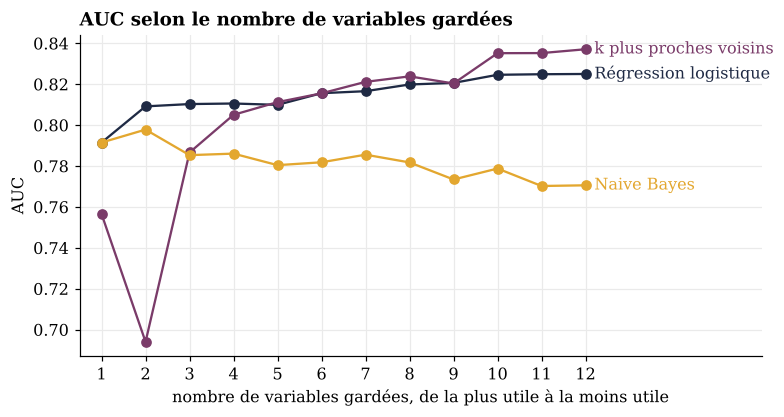

In [16]:
ordre = list(selection.index)
a_tester = {"Régression logistique": temoins["Régression logistique"],
            "k plus proches voisins": temoins["k plus proches voisins"],
            "Naive Bayes": GaussianNB()}
courbes = pd.DataFrame({nom: [notes_cv(modele, X_train[ordre[:k]], y_train)[0] for k in range(1, 13)]
                        for nom, modele in a_tester.items()}, index=range(1, 13))

fig, ax = plt.subplots(figsize=(8, 3.8))
for nom, couleur in zip(courbes.columns, [ENCRE, PRUNE, MIEL]):
    ax.plot(courbes.index, courbes[nom], marker="o", color=couleur)
    ax.text(12.2, courbes[nom].iloc[-1], nom, color=couleur, va="center")
ax.set_xlim(0.5, 16); ax.set_xticks(range(1, 13))
ax.set_xlabel("nombre de variables gardées, de la plus utile à la moins utile"); ax.set_ylabel("AUC")
ax.set_title("AUC selon le nombre de variables gardées")
plt.show()
courbes.round(3).T

La régression logistique et les voisins progressent quand on ajoute des mesures, puis se stabilisent vers 10. Les dernières n'apportent rien mais ne gênent pas.

Naive Bayes fait l'inverse. Il est à son meilleur avec 2 mesures (0.798) et descend à 0.771 avec les 12. Ce modèle traite chaque mesure comme une preuve indépendante. Quand deux mesures se répètent, il compte la même preuve deux fois.

Nous gardons donc les 12 mesures pour tous les modèles sauf Naive Bayes, dont le nombre de mesures sera réglé en partie 2.

In [17]:
import os
os.makedirs("donnees_preparees", exist_ok=True)
train.to_csv("donnees_preparees/train.csv", index=False)
test.to_csv("donnees_preparees/test.csv", index=False)
print("Fichiers enregistrés pour les parties 2 et 3,", len(train), "vins d'entraînement et", len(test), "vins de test")

Fichiers enregistrés pour les parties 2 et 3, 4256 vins d'entraînement et 1064 vins de test


Les vins d'entraînement et de test sont enregistrés pour les deux parties suivantes.

# Partie 2. Construire, régler et comprendre les cinq modèles

Projet 2 de Machine Learning 1, EFREI 2026-2027.

Cette partie reprend le jeu d'entraînement préparé en partie 1. Elle entraîne les cinq modèles du sujet, les règle, puis cherche à comprendre ce que chacun a appris. Le jeu de test n'est jamais ouvert ici. Tous les scores de cette partie viennent de la validation croisée expliquée en 1.7.

In [18]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_score, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.metrics import precision_recall_curve
from scipy.stats import loguniform

# Style commun des graphiques du groupe
ENCRE, PRUNE, MIEL, BRUME = "#1F2A44", "#7A3B69", "#E3A72F", "#C5CAD3"
plt.rcParams.update({
    "font.family": "serif", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#EAEAEA", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 12,
    "legend.frameon": False,
})
GRAINE = 42
pd.set_option("display.precision", 3)

In [19]:
train = pd.read_csv("donnees_preparees/train.csv")
variables = [c for c in train.columns if c not in ["quality", "type", "bon"]]
X_train, y_train = train[variables], train["bon"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
print(len(X_train), "vins d'entraînement,", len(variables), "variables,", f"{y_train.mean():.1%} de bons vins")

4256 vins d'entraînement, 12 variables, 19.0% de bons vins


## 2.1 Quels sont les cinq modèles, et lesquels sont linéaires ?

Nous comparons une régression logistique, qui est le seul modèle linéaire, à quatre modèles qui ne le sont pas. Un modèle linéaire sépare les bons vins des mauvais par une frontière droite. Les autres peuvent tracer une frontière plus souple.

| Modèle | Comment il décide | Linéaire | Ce qu'il suppose |
|---|---|---|---|
| Régression logistique | Il additionne les mesures, chacune multipliée par un poids, et transforme le total en probabilité | Oui | Que l'effet de chaque mesure s'ajoute à celui des autres |
| k plus proches voisins | Il regarde les k vins les plus ressemblants et compte combien sont bons | Non | Que deux vins proches ont la même qualité |
| Arbre de décision | Il pose une suite de questions du type « alcool inférieur à 10,6 ? » | Non | Rien de particulier |
| Naive Bayes | Il calcule la probabilité d'être bon d'après chaque mesure prise séparément, puis multiplie ces probabilités | Non | Que les mesures sont indépendantes et suivent une loi normale |
| SVM | Il cherche la frontière qui passe le plus loin possible des deux classes, et un noyau lui permet de la courber | Selon le noyau | Que la distance entre deux vins a un sens |

## 2.2 Que donnent-ils sans réglage ?

Sans réglage, la régression logistique et le SVM sont en tête, et l'arbre de décision est de loin le moins bon. Pour chaque modèle, nous relevons son score sur les vins qui ont servi à l'entraîner et son score sur les vins de validation.

In [20]:
modeles = {
    "Régression logistique": Pipeline([("echelle", StandardScaler()), ("modele", LogisticRegression(max_iter=2000))]),
    "k plus proches voisins": Pipeline([("echelle", StandardScaler()), ("modele", KNeighborsClassifier())]),
    "Arbre de décision": Pipeline([("modele", DecisionTreeClassifier(random_state=GRAINE))]),
    "Naive Bayes": Pipeline([("modele", GaussianNB())]),
    "SVM": Pipeline([("echelle", StandardScaler()), ("modele", SVC())]),
}

lignes = []
for nom, modele in modeles.items():
    notes = cross_validate(modele, X_train, y_train, cv=cv, scoring=["roc_auc", "f1"], return_train_score=True)
    lignes.append({"modèle": nom,
                   "AUC entraînement": notes["train_roc_auc"].mean(),
                   "AUC validation": notes["test_roc_auc"].mean(),
                   "F1 validation": notes["test_f1"].mean()})
depart = pd.DataFrame(lignes).set_index("modèle")
depart["écart d'AUC"] = depart["AUC entraînement"] - depart["AUC validation"]
depart.round(3)

,AUC entraînement,AUC validation,F1 validation,écart d'AUC
modèle,,,,
Régression logistique,0.828,0.825,0.370,0.003
k plus proches voisins,0.923,0.793,0.482,0.130
Arbre de décision,1.000,0.649,0.428,0.351
Naive Bayes,0.774,0.771,0.490,0.003
SVM,0.861,0.821,0.381,0.040


L'arbre obtient 1.000 sur les vins d'entraînement et seulement 0.649 en validation. Il a retenu les vins un par un au lieu d'apprendre une règle générale. La régression logistique et Naive Bayes ont au contraire presque le même score des deux côtés. La section 2.6 revient sur ces deux comportements.

Le F1-score de ce tableau utilise la décision par défaut de chaque modèle. Il ne classe pas les modèles dans le même ordre que l'AUC. Naive Bayes a par exemple le meilleur F1-score et l'une des moins bonnes AUC. La section 2.4 explique pourquoi.

## 2.3 Comment choisir les hyperparamètres ?

Nous essayons toutes les combinaisons d'une grille de valeurs et nous gardons celle qui obtient le meilleur score en validation croisée à 5 plis. Cette méthode s'appelle la recherche par grille. Un hyperparamètre est un réglage que le modèle n'apprend pas seul et qu'il faut lui fixer.

| Modèle | Réglage | Ce qu'il change |
|---|---|---|
| Régression logistique | `C` | Un petit C oblige les poids à rester petits, ce qui simplifie le modèle |
| Régression logistique et SVM | `class_weight` | Avec `balanced`, une erreur sur un bon vin coûte environ quatre fois plus qu'une erreur sur un mauvais |
| k plus proches voisins | `n_neighbors` | Avec peu de voisins le modèle suit chaque vin de près, avec beaucoup il fait une moyenne |
| k plus proches voisins | `weights` et `p` | Vote égal ou vote plus fort des voisins les plus proches, et façon de mesurer la distance |
| Arbre de décision | `max_depth`, `min_samples_leaf`, `criterion` | La taille de l'arbre, et le critère de choix des questions (Gini ou entropie) |
| Naive Bayes | nombre de mesures | On ajoute une par une la mesure qui aide le plus, comme annoncé en 1.11 |
| SVM | `kernel`, `C`, `gamma` | Frontière droite ou courbe. Un grand C tolère peu d'erreurs. Un grand gamma donne une frontière très sinueuse |

In [21]:
grilles = {
    "Régression logistique": {"modele__C": [0.01, 0.1, 1, 10, 100],
                              "modele__class_weight": [None, "balanced"]},
    "k plus proches voisins": {"modele__n_neighbors": [1, 3, 5, 9, 15, 25, 35, 51, 75],
                               "modele__weights": ["uniform", "distance"],
                               "modele__p": [1, 2]},
    "Arbre de décision": {"modele__max_depth": [2, 3, 4, 6, 8, 10, None],
                          "modele__min_samples_leaf": [1, 5, 10, 20, 50, 80],
                          "modele__criterion": ["gini", "entropy"]},
    "Naive Bayes": {"selection__n_features_to_select": [1, 2, 3, 4, 5, 6, 8, 10]},
    "SVM": [{"modele__kernel": ["rbf"], "modele__C": [0.3, 1, 3, 10], "modele__gamma": [0.003, 0.01, 0.03, 0.1, 0.3],
             "modele__class_weight": [None, "balanced"]},
            {"modele__kernel": ["linear"], "modele__C": [0.1, 1], "modele__class_weight": [None, "balanced"]}],
}

# Pour Naive Bayes, le réglage utile est le choix des variables (partie 1)
a_regler = dict(modeles)
a_regler["Naive Bayes"] = Pipeline([("selection", SequentialFeatureSelector(GaussianNB(), scoring="roc_auc", cv=5)),
                                    ("modele", GaussianNB())])

recherches = {}
lignes = []
for nom, modele in a_regler.items():
    debut = time.time()
    recherche = GridSearchCV(modele, grilles[nom], cv=cv, scoring={"auc": "roc_auc", "f1": "f1"},
                             refit="auc", n_jobs=-1, return_train_score=True)
    recherche.fit(X_train, y_train)
    recherches[nom] = recherche
    i = recherche.best_index_
    lignes.append({"modèle": nom,
                   "essais": len(recherche.cv_results_["params"]),
                   "durée (s)": round(time.time() - debut),
                   "AUC entraînement": recherche.cv_results_["mean_train_auc"][i],
                   "AUC validation": recherche.best_score_,
                   "écart type": recherche.cv_results_["std_test_auc"][i],
                   "F1 validation par défaut": recherche.cv_results_["mean_test_f1"][i],
                   "réglages retenus": {k.split("__")[1]: v for k, v in recherche.best_params_.items()}})
optimisation = pd.DataFrame(lignes).set_index("modèle")
optimisation["gain d'AUC"] = optimisation["AUC validation"] - depart["AUC validation"]
pd.set_option("display.max_colwidth", 90)
optimisation.round(3)

,essais,durée (s),AUC entraînement,AUC validation,écart type,F1 validation par défaut,réglages retenus,gain d'AUC
modèle,,,,,,,,
Régression logistique,10,2,0.828,0.825,0.017,0.370,"{'C': 1, 'class_weight': None}",0.000
k plus proches voisins,36,32,1.000,0.844,0.014,0.440,"{'n_neighbors': 25, 'p': 2, 'weights': 'distance'}",0.051
Arbre de décision,84,6,0.863,0.808,0.019,0.391,"{'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}",0.159
Naive Bayes,8,23,0.802,0.801,0.020,0.459,{'n_features_to_select': 6},0.030
SVM,44,78,0.885,0.844,0.013,0.551,"{'C': 1, 'class_weight': 'balanced', 'gamma': 0.1, 'kernel': 'rbf'}",0.023


Les deux modèles qui retenaient les vins un par un sont ceux qui gagnent le plus. L'arbre gagne 0.159 d'AUC et les voisins 0.051. Les voisins passent de 5 à 25 voisins, et l'arbre demande au moins 50 vins dans chaque feuille. Dans les deux cas, le modèle réglé s'appuie sur plus de vins pour chaque décision.

La régression logistique ne gagne rien. Elle n'a que 12 poids à apprendre pour 4256 vins, elle ne risque donc pas de retenir les vins un par un.

Le SVM gagne surtout grâce à `class_weight="balanced"`. Sans cette option, il cherche à faire le moins d'erreurs possible au total. Comme les mauvais vins sont quatre fois plus nombreux, il place sa frontière pour bien classer les mauvais et néglige les bons. Avec l'option, les deux classes pèsent autant et la frontière se replace entre elles. Pour la régression logistique, la même option ne change presque pas l'AUC, car elle décale surtout les probabilités sans beaucoup modifier l'ordre des vins.

Deux chiffres de ce tableau demandent une précision. Les voisins ont une AUC de 1 sur les vins d'entraînement. Avec un vote plus fort pour les voisins les plus proches, chaque vin d'entraînement est son propre voisin à distance nulle, ce score ne veut donc rien dire. La colonne du F1-score par défaut est expliquée en 2.4.

## 2.4 Pourquoi régler avec l'AUC plutôt qu'avec le F1 ?

Parce que le F1-score par défaut récompense les modèles qui retiennent trop les vins d'entraînement. Pour le montrer, nous regardons le réglage que le F1-score aurait choisi pour chaque modèle. Nous calculons aussi le meilleur F1-score que chaque réglage peut atteindre quand la décision est bien placée, ce que la partie 3 explique en 3.2.

In [22]:
def meilleur_f1_possible(modele):
    """F1-score obtenu en choisissant le meilleur seuil, sur des prédictions hors pli."""
    methode = "predict_proba" if hasattr(modele[-1], "predict_proba") else "decision_function"
    notes = cross_val_predict(modele, X_train, y_train, cv=cv, method=methode)
    notes = notes[:, 1] if notes.ndim == 2 else notes
    precisions, rappels, _ = precision_recall_curve(y_train, notes)
    return (2 * precisions * rappels / (precisions + rappels + 1e-12)).max()

lignes = []
for nom, recherche in recherches.items():
    resultats = pd.DataFrame(recherche.cv_results_)
    j = resultats["mean_test_f1"].idxmax()                       # le réglage qu'aurait choisi le F1-score
    modele_f1 = clone(a_regler[nom]).set_params(**resultats.loc[j, "params"])
    lignes.append({"modèle": nom,
                   "réglage choisi par le F1": {k.split("__")[1]: v for k, v in resultats.loc[j, "params"].items()},
                   "son F1 au seuil 0,5": resultats.loc[j, "mean_test_f1"],
                   "son AUC": resultats.loc[j, "mean_test_auc"],
                   "son F1 au meilleur seuil": meilleur_f1_possible(modele_f1),
                   "F1 au meilleur seuil du réglage choisi par l'AUC": meilleur_f1_possible(recherche.best_estimator_)})
comparaison_criteres = pd.DataFrame(lignes).set_index("modèle")
comparaison_criteres.round(3)

,réglage choisi par le F1,"son F1 au seuil 0,5",son AUC,son F1 au meilleur seuil,F1 au meilleur seuil du réglage choisi par l'AUC
modèle,,,,,
Régression logistique,"{'C': 0.01, 'class_weight': 'balanced'}",0.537,0.823,0.550,0.543
k plus proches voisins,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}",0.498,0.785,0.527,0.568
Arbre de décision,"{'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 20}",0.450,0.798,0.520,0.515
Naive Bayes,{'n_features_to_select': 10},0.500,0.785,0.503,0.515
SVM,"{'C': 1, 'class_weight': 'balanced', 'gamma': 0.1, 'kernel': 'rbf'}",0.551,0.844,0.566,0.566


Pour les voisins, le F1-score aurait choisi 3 voisins au lieu de 25. Ce réglage a une AUC de 0.785 seulement. Et même avec la décision bien placée, son F1-score plafonne à 0.527, contre 0.568 pour le réglage choisi par l'AUC.

L'explication est la suivante. Les bons vins sont rares, donc un modèle prudent annonce rarement un bon vin et son F1-score par défaut est faible. Un modèle qui a retenu les vins un par un répond de façon plus tranchée, il annonce plus de bons vins et son F1-score paraît meilleur. Le F1-score par défaut mélange donc deux choses, la qualité du classement et la façon de trancher.

Nous séparons ces deux questions. L'AUC sert à régler et à choisir le modèle. Le F1-score sert ensuite à régler la décision, en partie 3.

## 2.5 La recherche aléatoire fait-elle aussi bien ?

Oui, elle arrive au même score que la grille avec beaucoup moins d'essais. Au lieu d'essayer toutes les combinaisons, elle en tire quelques-unes au hasard. Nous la comparons à la grille sur le SVM, qui est le modèle le plus long à régler.

In [23]:
debut = time.time()
recherche_aleatoire = RandomizedSearchCV(
    modeles["SVM"].set_params(modele__class_weight="balanced"),
    {"modele__C": loguniform(0.3, 10), "modele__gamma": loguniform(0.003, 0.3)},
    n_iter=10, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=GRAINE).fit(X_train, y_train)
duree_aleatoire = time.time() - debut

print(f"Recherche par grille   {optimisation.loc['SVM', 'essais']} essais, {optimisation.loc['SVM', 'durée (s)']} s, AUC {optimisation.loc['SVM', 'AUC validation']:.3f}")
print(f"Recherche aléatoire    10 essais, {duree_aleatoire:.0f} s, AUC {recherche_aleatoire.best_score_:.3f}")
print("Réglages trouvés au hasard", {k.split("__")[1]: round(v, 3) for k, v in recherche_aleatoire.best_params_.items()})

Recherche par grille   44 essais, 78 s, AUC 0.844
Recherche aléatoire    10 essais, 8 s, AUC 0.845
Réglages trouvés au hasard {'C': np.float64(3.907), 'gamma': np.float64(0.047)}


Avec 10 essais au lieu de 44, la recherche aléatoire obtient 0.845 contre 0.844 pour la grille. La grille passe du temps sur des zones entières qui ne donnent rien, comme tous les essais avec un grand gamma. La recherche aléatoire ne garantit pas de trouver le meilleur réglage, mais elle essaie des valeurs intermédiaires que la grille ne contient pas.

Nous gardons les réglages de la grille, qui reste rapide sur ce projet. Avec plus de données ou plus de réglages, la recherche aléatoire serait le bon point de départ.

## 2.6 Comment éviter un modèle trop rigide ou trop collé aux données ?

Il faut régler la souplesse du modèle pour obtenir le meilleur score de validation, et non le meilleur score d'entraînement. Un modèle trop rigide ne peut pas saisir ce qui distingue les bons vins. On dit qu'il a du biais. Un modèle trop souple retient les particularités des vins d'entraînement, qui ne se retrouvent pas sur de nouveaux vins. On dit qu'il a de la variance.

Pour l'arbre, les voisins et le SVM, nous faisons varier un seul réglage et nous traçons les deux scores. Le cercle marque le meilleur score de validation.

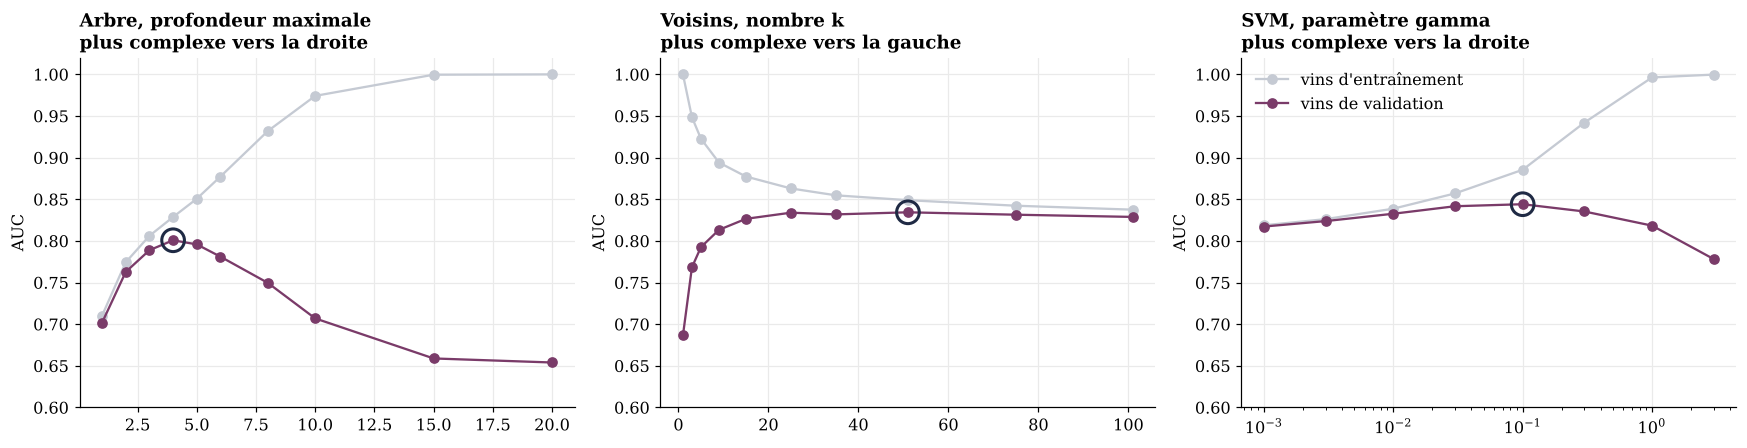

In [24]:
def courbe_de_complexite(ax, modele, parametre, valeurs, titre, echelle_log=False):
    notes_train, notes_val = validation_curve(modele, X_train, y_train, param_name=parametre,
                                              param_range=valeurs, cv=cv, scoring="roc_auc", n_jobs=-1)
    ax.plot(valeurs, notes_train.mean(axis=1), marker="o", color=BRUME, label="vins d'entraînement")
    ax.plot(valeurs, notes_val.mean(axis=1), marker="o", color=PRUNE, label="vins de validation")
    meilleur = notes_val.mean(axis=1).argmax()
    ax.scatter(valeurs[meilleur], notes_val.mean(axis=1)[meilleur], s=220, facecolors="none", edgecolors=ENCRE, linewidths=2, zorder=5)
    if echelle_log:
        ax.set_xscale("log")
    ax.set_ylim(0.6, 1.02); ax.set_title(titre); ax.set_ylabel("AUC")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
courbe_de_complexite(axes[0], modeles["Arbre de décision"], "modele__max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 15, 20],
                     "Arbre, profondeur maximale\nplus complexe vers la droite")
courbe_de_complexite(axes[1], modeles["k plus proches voisins"], "modele__n_neighbors", [1, 3, 5, 9, 15, 25, 35, 51, 75, 101],
                     "Voisins, nombre k\nplus complexe vers la gauche")
courbe_de_complexite(axes[2], modeles["SVM"], "modele__gamma", [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3],
                     "SVM, paramètre gamma\nplus complexe vers la droite", echelle_log=True)
axes[2].legend(loc="upper left")
plt.tight_layout(); plt.show()

Les trois courbes ont la même forme. Du côté souple, le score d'entraînement monte vers 1 pendant que le score de validation baisse. Du côté rigide, les deux scores sont proches et bas. Le meilleur réglage est entre les deux.

Pour l'arbre, chaque niveau ajouté au-delà de 4 améliore l'entraînement et dégrade la validation. La grille retient pourtant une profondeur de 8. Ce n'est pas contradictoire, car elle impose en même temps au moins 50 vins par feuille, ce qui empêche l'arbre de créer des règles trop fines.

Le tableau suivant fait le bilan pour les cinq modèles réglés.

In [25]:
bilan = optimisation[["AUC entraînement", "AUC validation"]].copy()
bilan["écart"] = bilan["AUC entraînement"] - bilan["AUC validation"]
bilan["écart avant réglage"] = depart["écart d'AUC"]
bilan.sort_values("AUC validation", ascending=False).round(3)

,AUC entraînement,AUC validation,écart,écart avant réglage
modèle,,,,
SVM,0.885,0.844,0.041,0.040
k plus proches voisins,1.000,0.844,0.156,0.130
Régression logistique,0.828,0.825,0.003,0.003
Arbre de décision,0.863,0.808,0.056,0.351
Naive Bayes,0.802,0.801,0.001,0.003


La régression logistique et Naive Bayes ont le même score en entraînement et en validation. Ils sont stables mais plafonnent, leur limite est le biais. L'arbre était le modèle le plus collé aux données, avec un écart de 0.351 avant réglage. Le réglage ramène cet écart à 0.056, mais son score reste en retrait. Le SVM a la meilleure validation avec un écart modéré de 0.041. L'écart des voisins ne se lit pas, pour la raison donnée en 2.3.

## 2.7 Qu'a appris chaque modèle ?

Chaque modèle confirme que l'alcool est la mesure la plus utile, et leurs différences montrent que la qualité dépend de la façon dont les mesures se combinent.

**La régression logistique**

In [26]:
# Les cinq modèles avec leurs meilleurs réglages, entraînés sur tous les vins d'entraînement
optimises = {nom: recherche.best_estimator_ for nom, recherche in recherches.items()}
optimises["SVM"].set_params(modele__probability=True, modele__random_state=GRAINE)   # pour obtenir des probabilités
for modele in optimises.values():
    modele.fit(X_train, y_train)

Corrélation directe entre le sucre résiduel et la cible -0.08


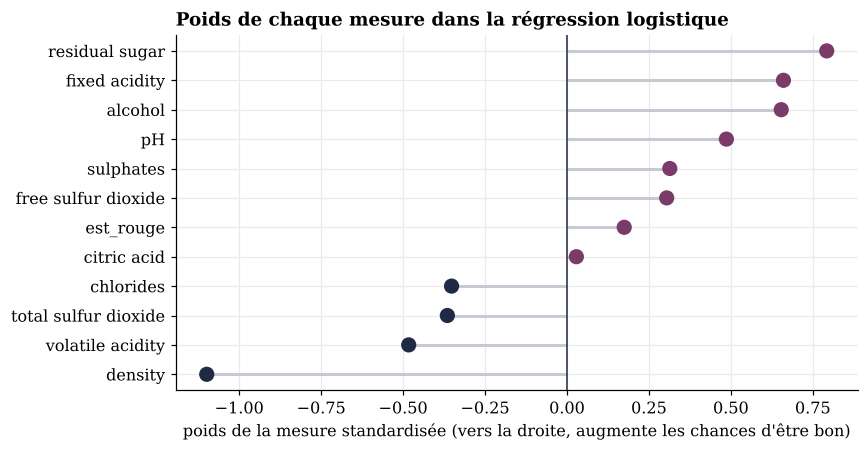

In [27]:
logistique = optimises["Régression logistique"].named_steps["modele"]
poids = pd.Series(logistique.coef_[0], index=variables).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hlines(range(len(poids)), 0, poids, color=BRUME, linewidth=2)
ax.scatter(poids, range(len(poids)), color=[PRUNE if v > 0 else ENCRE for v in poids], s=80, zorder=3)
ax.axvline(0, color=ENCRE, linewidth=1)
ax.set_yticks(range(len(poids))); ax.set_yticklabels(poids.index)
ax.set_xlabel("poids de la mesure standardisée (vers la droite, augmente les chances d'être bon)")
ax.set_title("Poids de chaque mesure dans la régression logistique")
plt.show()
print(f"Corrélation directe entre le sucre résiduel et la cible {X_train['residual sugar'].corr(y_train):+.2f}")

Le plus gros poids positif est celui du sucre résiduel. On pourrait en conclure que le sucre est le premier facteur de qualité. Ce serait une erreur, car le lien direct entre le sucre et la cible est légèrement négatif.

Un poids se lit en supposant que toutes les autres mesures restent égales. Or la densité dépend presque entièrement de l'alcool et du sucre, comme vu en 1.6. À densité égale, un vin plus sucré est forcément plus alcoolisé, puisque l'alcool compense le poids du sucre. Le poids du sucre et celui de la densité sont donc deux façons indirectes de dire que le vin a plus d'alcool. Quand des mesures se répètent, leurs poids ne s'interprètent pas un par un.

En 1.5, nous avions vu que certaines mesures n'ont pas le même effet chez les rouges et chez les blancs. Nous pensions que cela expliquait le retard de la régression logistique sur les meilleurs modèles. Nous testons cette idée, ainsi qu'une seconde.

In [28]:
# Que manque-t-il à la régression logistique ? Deux explications possibles sont testées.
modele_logistique = optimises["Régression logistique"]

# Explication 1, il lui faudrait un poids différent pour les rouges (interactions avec la couleur)
X_couleur = X_train.copy()
for variable in variables[:-1]:
    X_couleur[variable + " x rouge"] = X_train[variable] * X_train["est_rouge"]

# Explication 2, il lui faudrait pouvoir combiner les mesures entre elles (carrés et produits)
avec_produits = Pipeline([("echelle", StandardScaler()), ("produits", PolynomialFeatures(2, include_bias=False)),
                          ("modele", LogisticRegression(max_iter=5000, C=0.1))])

essais = pd.Series({
    "Régression logistique de départ": cross_val_score(modele_logistique, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
    "avec un poids différent pour les rouges": cross_val_score(modele_logistique, X_couleur, y_train, cv=cv, scoring="roc_auc").mean(),
    "avec les carrés et les produits de mesures": cross_val_score(avec_produits, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
}, name="AUC validation")
essais.round(3)

,AUC validation
Régression logistique de départ,0.825
avec un poids différent pour les rouges,0.826
avec les carrés et les produits de mesures,0.839


Notre première idée était fausse. Donner à la régression logistique un poids différent pour les rouges ne change presque rien (0.826 contre 0.825). En revanche, lui donner les produits de mesures la fait monter à 0.839, presque au niveau des meilleurs modèles. Ce qui lui manque, ce sont donc les combinaisons entre mesures. L'effet d'une mesure sur la qualité dépend des autres mesures du même vin, ce qui correspond à l'idée d'un vin équilibré.

**L'arbre de décision**

Arbre de profondeur 8 avec 50 feuilles


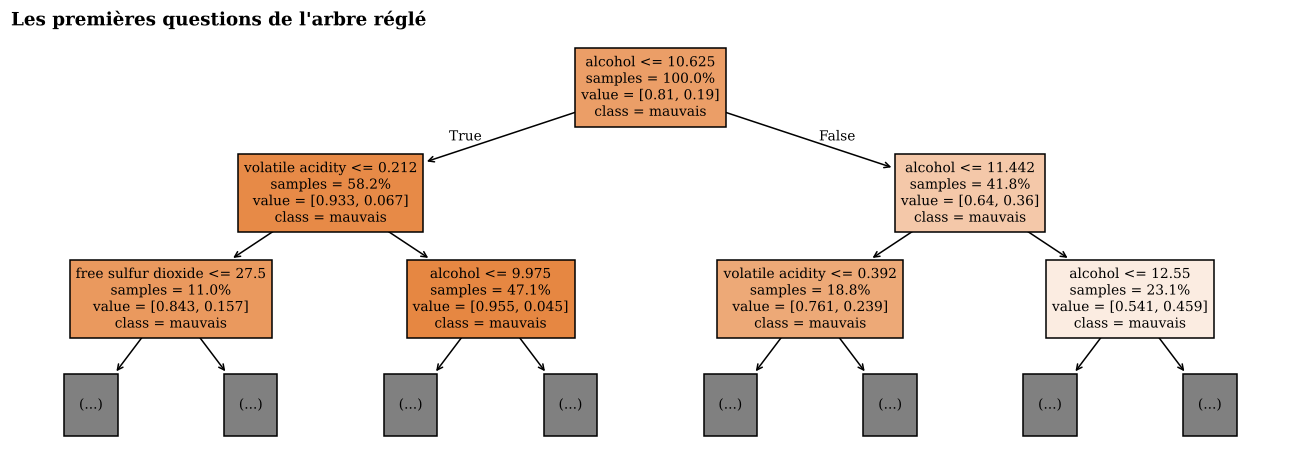

In [29]:
arbre = optimises["Arbre de décision"].named_steps["modele"]
plt.figure(figsize=(15, 5))
plot_tree(arbre, max_depth=2, feature_names=variables, class_names=["mauvais", "bon"],
          filled=True, impurity=False, proportion=True, fontsize=9)
plt.title("Les premières questions de l'arbre réglé")
plt.show()
print(f"Arbre de profondeur {arbre.get_depth()} avec {arbre.get_n_leaves()} feuilles")

La première question de l'arbre porte sur l'alcool, et l'alcool revient aux niveaux suivants avec l'acidité volatile. L'arbre retrouve donc les deux mesures repérées en 1.5. Sa faiblesse vient de sa façon de travailler. La qualité augmente peu à peu avec l'alcool, et l'arbre doit imiter cette pente avec une série de seuils, comme un escalier.

**Naive Bayes**

In [30]:
# Naive Bayes souffre-t-il vraiment des mesures qui se répètent ? On les décorrèle avant de les lui donner.
bayes_acp = Pipeline([("echelle", StandardScaler()), ("acp", PCA()), ("modele", GaussianNB())])

essais_bayes = pd.Series({
    "Naive Bayes avec les 12 mesures": cross_val_score(GaussianNB(), X_train, y_train, cv=cv, scoring="roc_auc").mean(),
    "Naive Bayes après décorrélation des mesures": cross_val_score(bayes_acp, X_train, y_train, cv=cv, scoring="roc_auc").mean(),
    "Naive Bayes avec les mesures sélectionnées": optimisation.loc["Naive Bayes", "AUC validation"],
}, name="AUC validation")

selection_bayes = optimises["Naive Bayes"].named_steps["selection"]
print("Mesures gardées par la sélection", list(X_train.columns[selection_bayes.get_support()]))
essais_bayes.round(3)

Mesures gardées par la sélection ['volatile acidity', 'citric acid', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol']


,AUC validation
Naive Bayes avec les 12 mesures,0.771
Naive Bayes après décorrélation des mesures,0.795
Naive Bayes avec les mesures sélectionnées,0.801


En 1.11, Naive Bayes se dégradait quand on lui donnait des mesures qui se répètent. Nous le vérifions autrement. L'analyse en composantes principales remplace les 12 mesures par 12 combinaisons qui ne sont plus corrélées entre elles. Avec ces combinaisons, Naive Bayes passe de 0.771 à 0.795. C'est bien la répétition entre mesures qui le gênait. La sélection de mesures retenue en 2.3 arrive au même résultat (0.801) en restant plus simple à expliquer.

**Le SVM et les k plus proches voisins**

In [31]:
svm = optimises["SVM"].named_steps["modele"]
part_supports = svm.n_support_.sum() / len(X_train)
print(f"Le SVM utilise {svm.n_support_.sum()} vecteurs supports sur {len(X_train)} vins, soit {part_supports:.0%}")

Le SVM utilise 2289 vecteurs supports sur 4256 vins, soit 54%


54% des vins d'entraînement sont des vecteurs supports, c'est-à-dire des vins proches de la frontière ou du mauvais côté. Dans un cas facile, quelques vins suffiraient à fixer la frontière. Ici il en faut plus de la moitié, ce qui montre que les bons et les mauvais vins sont très mélangés.

Le SVM à noyau gaussien et les k plus proches voisins raisonnent tous les deux par ressemblance. Les voisins comparent directement un vin aux vins les plus proches de lui. Le SVM gaussien décide aussi d'après la distance du vin à ses vecteurs supports, et les plus proches comptent le plus. Dans les deux cas, toutes les mesures du vin sont prises en compte ensemble. Ce sont justement les deux meilleurs modèles.

| Modèle | Pourquoi ce résultat est cohérent avec le vin |
|---|---|
| k plus proches voisins | Deux vins de même composition ont de bonnes chances d'avoir le même goût, donc une note proche |
| SVM | Sa frontière courbe tient compte des combinaisons entre mesures, et il tolère des vins mal classés près de la frontière |
| Régression logistique | Elle saisit bien l'effet de l'alcool mais additionne les mesures sans les combiner |
| Arbre de décision | Il découpe en tranches une qualité qui évolue progressivement |
| Naive Bayes | Les mesures d'un vin sont liées par la chimie, son hypothèse d'indépendance est donc fausse |

## 2.8 Combiner les modèles aide-t-il ?

Très peu, car nos modèles hésitent sur les mêmes vins. Combiner des modèles n'est utile que s'ils se trompent sur des vins différents. Nous commençons donc par regarder si leurs probabilités se ressemblent.

In [32]:
# Les modèles hésitent-ils sur les mêmes vins ? On compare leurs probabilités, calculées en validation croisée.
probas_cv = pd.DataFrame({nom: cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
                          for nom, modele in optimises.items()})
accord = probas_cv.corr()
accord.round(2)

,Régression logistique,k plus proches voisins,Arbre de décision,Naive Bayes,SVM
Régression logistique,1.00,0.81,0.80,0.88,0.83
k plus proches voisins,0.81,1.00,0.77,0.80,0.88
Arbre de décision,0.80,0.77,1.00,0.76,0.76
Naive Bayes,0.88,0.80,0.76,1.00,0.79
SVM,0.83,0.88,0.76,0.79,1.00


Les probabilités des cinq modèles sont très liées, avec des corrélations entre 0.76 et 0.88. Nous testons ensuite les trois méthodes d'ensemble du cours.

| Méthode | Principe |
|---|---|
| Forêt aléatoire | 300 arbres entraînés chacun sur un tirage différent des vins, puis un vote |
| AdaBoost | De très petits arbres entraînés à la suite, chacun insistant sur les erreurs du précédent |
| Stacking | Une régression logistique apprend à combiner les réponses de nos cinq modèles |

In [33]:
ensembles = {
    "Forêt aléatoire (bagging)": RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1),
    "AdaBoost (boosting)": AdaBoostClassifier(n_estimators=200, random_state=GRAINE),
    "Stacking des 5 modèles": StackingClassifier(estimators=list(optimises.items()),
                                                 final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1),
}
lignes = []
for nom, modele in ensembles.items():
    notes = cross_validate(modele, X_train, y_train, cv=cv, scoring="roc_auc", return_train_score=True)
    lignes.append({"modèle": nom, "AUC entraînement": notes["train_score"].mean(),
                   "AUC validation": notes["test_score"].mean(), "écart type": notes["test_score"].std()})
resultats_ensembles = pd.DataFrame(lignes).set_index("modèle")
resultats_ensembles.round(3)

,AUC entraînement,AUC validation,écart type
modèle,,,
Forêt aléatoire (bagging),1.000,0.850,0.022
AdaBoost (boosting),0.844,0.820,0.015
Stacking des 5 modèles,1.000,0.854,0.014


La forêt aléatoire fait passer l'arbre de 0.808 à 0.850. Le défaut de l'arbre était la variance, et faire voter 300 arbres différents la réduit.

AdaBoost est en dessous. Il insiste sur les vins mal classés, et nous verrons en partie 3 que ces vins sont souvent ceux dont la note est la plus discutable.

La forêt et le stacking ne dépassent le SVM (0.844) que de 0.010 au plus. C'est moins que l'écart type entre plis, qui est d'environ 0.013. Aucune méthode ne dépasse nettement 0,85. Nous restons donc sur les cinq modèles du sujet pour la partie 3.

In [34]:
os.makedirs("modeles", exist_ok=True)
joblib.dump({"modeles": optimises, "optimisation": optimisation}, "modeles/modeles_optimises.joblib")
print("Cinq modèles réglés enregistrés pour la partie 3")

Cinq modèles réglés enregistrés pour la partie 3


# Partie 3. Choisir le modèle et juger sa fiabilité

Projet 2 de Machine Learning 1, EFREI 2026-2027.

Cette partie recharge les cinq modèles réglés en partie 2. Elle choisit le meilleur et explique pourquoi il gagne, fixe sa règle de décision, puis ouvre le jeu de test une seule fois pour mesurer ce qu'il vaut, comprendre ses erreurs et en tirer les limites.

In [35]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_curve, roc_curve, confusion_matrix)

# Style commun des graphiques du groupe
ENCRE, PRUNE, MIEL, BRUME = "#1F2A44", "#7A3B69", "#E3A72F", "#C5CAD3"
plt.rcParams.update({
    "font.family": "serif", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#EAEAEA", "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 12,
    "legend.frameon": False,
})
GRAINE = 42
pd.set_option("display.precision", 3)

In [36]:
train = pd.read_csv("donnees_preparees/train.csv")
test = pd.read_csv("donnees_preparees/test.csv")
variables = [c for c in train.columns if c not in ["quality", "type", "bon"]]
X_train, y_train = train[variables], train["bon"]
X_test, y_test = test[variables], test["bon"]

paquet = joblib.load("modeles/modeles_optimises.joblib")
optimises, optimisation = paquet["modeles"], paquet["optimisation"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
print(len(X_train), "vins d'entraînement,", len(X_test), "vins de test, cinq modèles réglés chargés")

4256 vins d'entraînement, 1064 vins de test, cinq modèles réglés chargés


## 3.1 Quel modèle est le meilleur, et sur quoi se base-t-on ?

Pour comparer les modèles nous utilisons l'AUC. Elle vérifie que le modèle donne en général une probabilité plus haute aux bons vins qu'aux mauvais. Elle vaut 0,5 pour un modèle qui répondrait au hasard et 1 pour un modèle qui donnerait toujours une probabilité plus haute à un bon vin qu'à un mauvais. Elle ne dépend pas du seuil à partir duquel on dit bon, que nous ne fixerons qu'en 3.2. On peut donc comparer la qualité des modèles avant de régler leur décision.

Les écarts entre modèles sont faibles et un seul découpage pourrait avantager un modèle par chance. Un découpage est une façon de partager les vins d'entraînement entre ceux qui servent à apprendre et ceux qui servent à noter le modèle. La validation croisée de la section 1.7 en fait 5. Nous la répétons 5 fois en mélangeant les vins différemment à chaque fois, ce qui donne 25 notes par modèle. Les cinq modèles sont notés sur exactement les mêmes découpages, et nous comptons sur combien de découpages le premier fait mieux que chacun des autres.

Modèle retenu avant d'ouvrir le jeu de test, SVM
Le même SVM avec un noyau linéaire obtient une AUC moyenne de 0.824


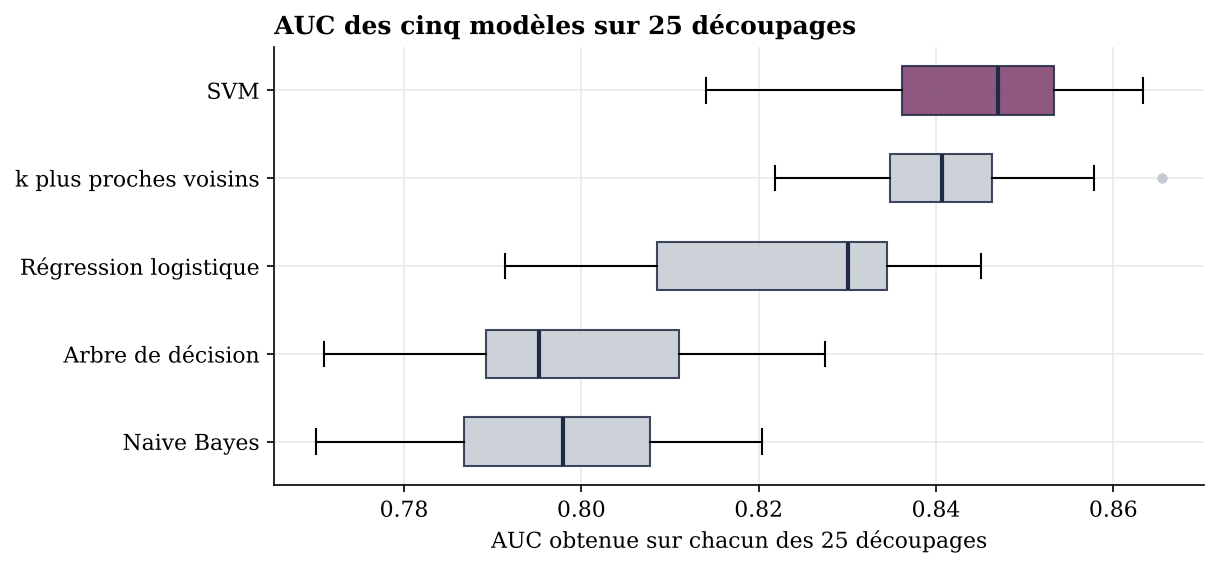

,AUC moyenne,écart type,découpages où le SVM fait mieux (sur 25)
SVM,0.843,0.013,0
k plus proches voisins,0.840,0.011,17
Régression logistique,0.825,0.015,25
Arbre de décision,0.799,0.015,25
Naive Bayes,0.798,0.014,25


In [37]:
# 25 découpages, soit une validation croisée à 5 plis répétée 5 fois avec des tirages différents
cv25 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=GRAINE)

a_comparer = dict(optimises)
a_comparer["SVM"] = clone(optimises["SVM"]).set_params(modele__probability=False)   # même modèle, calcul plus rapide

auc_25 = pd.DataFrame({nom: cross_val_score(modele, X_train, y_train, cv=cv25, scoring="roc_auc", n_jobs=-1)
                       for nom, modele in a_comparer.items()})

classement = pd.DataFrame({"AUC moyenne": auc_25.mean(), "écart type": auc_25.std()}).sort_values("AUC moyenne", ascending=False)
choisi = classement.index[0]
classement[f"découpages où le {choisi} fait mieux (sur 25)"] = [(auc_25[choisi] > auc_25[nom]).sum() for nom in classement.index]

# Le noyau linéaire, déjà testé en partie 2, est remis sur les mêmes 25 découpages pour comparer
svm_lineaire = clone(a_comparer["SVM"]).set_params(modele__kernel="linear")
auc_lineaire = cross_val_score(svm_lineaire, X_train, y_train, cv=cv25, scoring="roc_auc", n_jobs=-1)

# Une boîte par modèle avec ses 25 AUC, le modèle retenu en violet et en haut
ordre = list(classement.index[::-1])
fig, ax = plt.subplots(figsize=(8, 3.8))
boites = ax.boxplot([auc_25[nom] for nom in ordre], orientation="horizontal", widths=0.55, patch_artist=True,
                    medianprops=dict(color=ENCRE, linewidth=2),
                    flierprops=dict(marker="o", markersize=4, markerfacecolor=BRUME, markeredgecolor=BRUME))
for boite, nom in zip(boites["boxes"], ordre):
    boite.set(facecolor=PRUNE if nom == choisi else BRUME, edgecolor=ENCRE, alpha=0.85)
ax.set_yticks(range(1, len(ordre) + 1)); ax.set_yticklabels(ordre)
ax.set_xlabel("AUC obtenue sur chacun des 25 découpages")
ax.set_title("AUC des cinq modèles sur 25 découpages")
plt.show()

print("Modèle retenu avant d'ouvrir le jeu de test,", choisi)
print(f"Le même SVM avec un noyau linéaire obtient une AUC moyenne de {auc_lineaire.mean():.3f}")
classement.round(3)

Chaque boîte résume les 25 AUC d'un modèle. Le trait au milieu est la médiane, c'est à dire la valeur du milieu quand on range les 25 AUC. La boîte contient la moitié des découpages, ceux du milieu, et les moustaches vont jusqu'aux valeurs les plus éloignées. Plus une boîte est à droite, meilleur est le modèle, et plus elle est étroite, plus ses résultats sont réguliers d'un découpage à l'autre.

La boîte du SVM est la plus à droite, avec une AUC moyenne de 0,843. Il fait mieux que la régression logistique, l'arbre et Naive Bayes sur les 25 découpages, et leurs boîtes sont nettement à gauche de la sienne. Celle des k plus proches voisins, à 0,840 de moyenne, chevauche largement celle du SVM et elle est même un peu plus étroite. Sur un seul découpage, on ne pourrait donc pas départager ces deux modèles. C'est pour cela que nous comptons les découpages gagnés. Le SVM fait mieux que les voisins sur 17 découpages sur 25, l'écart est petit mais il va presque toujours dans le même sens. Nous retenons donc le SVM, en gardant en tête que les voisins seraient un choix presque aussi bon.

C'est aussi le modèle qui offrait le meilleur compromis entre biais et variance en 2.6. Avec un noyau linéaire, déjà écarté par la recherche par grille en 2.3, le même SVM retombe ici à 0,824, au niveau de la régression logistique. Cela confirme que c'est sa frontière courbe qui fait la différence.

Ce choix est fait avant d'ouvrir le jeu de test.

### Pourquoi ces deux modèles sont-ils les meilleurs pour juger un vin ?

Le classement s'explique par la façon dont un vin est jugé. Un dégustateur ne note pas l'alcool d'un côté et l'acidité de l'autre, il juge un goût d'ensemble. Un vin plaît quand ses mesures s'équilibrent entre elles, par exemple un degré d'alcool élevé avec peu d'acidité volatile. Deux vins dont la composition est très proche ont donc un goût proche et reçoivent en général une note proche.

La section 2.7 a montré que les k plus proches voisins et le SVM à noyau gaussien raisonnent tous les deux par ressemblance entre vins, en regardant toutes les mesures ensemble. C'est exactement ce qu'il faut pour tenir compte de cet équilibre, et c'est pourquoi ils arrivent en tête. Les trois autres modèles reposent sur des hypothèses qui correspondent moins bien au vin.

## 3.2 Que donne le modèle, et à partir de quelle probabilité dit-on « bon » ?

Le modèle ne répond pas directement bon ou pas bon. Pour chaque vin il donne une probabilité d'être bon, par exemple 0,62, et c'est un seuil qui transforme cette probabilité en décision. Si la probabilité dépasse le seuil, on dit bon. Le seuil habituel est 0,5.

Comme seulement 19 % des vins sont bons, le modèle donne rarement plus de 0,5 et il rate alors la plupart des bons vins. Nous cherchons donc le seuil qui donne le meilleur F1-score. Changer le seuil ne change pas le modèle, seulement la décision. Il est choisi sur les vins d'entraînement grâce à la validation croisée et jamais sur le test.

In [38]:
def meilleur_seuil(y_vrai, probas):
    """Seuil de probabilité qui donne le meilleur F1-score."""
    precisions, rappels, seuils_possibles = precision_recall_curve(y_vrai, probas)
    f1 = 2 * precisions * rappels / (precisions + rappels + 1e-12)
    return seuils_possibles[f1[:-1].argmax()]

# Probabilités calculées en validation croisée, chaque vin est noté par un modèle qui ne l'a pas vu
probas_cv = {nom: cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
             for nom, modele in optimises.items()}
seuils = {nom: meilleur_seuil(y_train, p) for nom, p in probas_cv.items()}

lignes = []
for nom, p in probas_cv.items():
    lignes.append({"modèle": nom,
                   "part des probabilités au-dessus de 0,5": (p >= 0.5).mean(),
                   "rappel au seuil 0,5": recall_score(y_train, p >= 0.5),
                   "F1 au seuil 0,5": f1_score(y_train, p >= 0.5),
                   "seuil retenu": seuils[nom],
                   "rappel au seuil retenu": recall_score(y_train, p >= seuils[nom]),
                   "F1 au seuil retenu": f1_score(y_train, p >= seuils[nom])})
tableau_seuils = pd.DataFrame(lignes).set_index("modèle")
tableau_seuils.round(3)

,"part des probabilités au-dessus de 0,5","rappel au seuil 0,5","F1 au seuil 0,5",seuil retenu,rappel au seuil retenu,F1 au seuil retenu
modèle,,,,,,
Régression logistique,0.094,0.276,0.370,0.221,0.736,0.543
k plus proches voisins,0.101,0.338,0.441,0.290,0.693,0.568
Arbre de décision,0.121,0.328,0.402,0.226,0.703,0.515
Naive Bayes,0.156,0.418,0.459,0.336,0.601,0.515
SVM,0.117,0.359,0.444,0.264,0.732,0.566


Le SVM ne donne une probabilité supérieure à 0,5 qu'à 12 % des vins. Avec ce seuil il ne retrouve que 36 % des bons vins. Avec un seuil de 0,26 il en retrouve 73 % et son F1-score passe de 0,444 à 0,566. Le même constat vaut pour les cinq modèles, qui ont tous un seuil retenu entre 0,22 et 0,34.

Une remarque sur le SVM. Son F1-score au seuil 0,5 vaut ici 0,444 alors que le tableau de la section 2.3 donnait 0,551. Ce n'est pas une erreur. En partie 2 la recherche par grille utilisait la réponse directe du SVM, c'est à dire le côté de la frontière où tombe le vin. Ici nous utilisons sa probabilité comparée à 0,5, et ces deux façons de décider ne donnent pas la même réponse pour tous les vins. La différence disparaît une fois le seuil réglé.

Le graphique suivant montre d'où vient ce problème. Il compare les probabilités données par le SVM aux vrais bons vins et aux vrais mauvais vins, toujours calculées en validation croisée sur les vins d'entraînement.

Probabilité médiane des mauvais vins 0.06, des bons vins 0.43
Bons vins au-dessus de 0,5 36%, au-dessus du seuil retenu 73%, sous 0,1 10%
Au seuil retenu, 591 bons vins retrouvés et 691 mauvais vins annoncés bons (20% des mauvais)


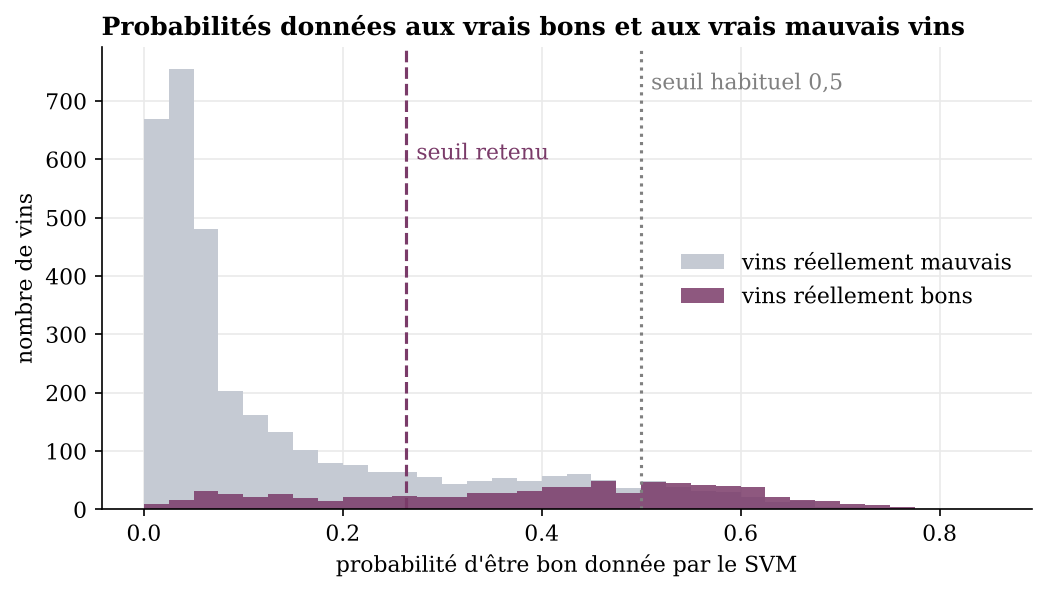

In [39]:
# Probabilités données par le SVM aux vrais bons vins et aux vrais mauvais vins (validation croisée)
p_bons = probas_cv[choisi][y_train.values == 1]
p_mauvais = probas_cv[choisi][y_train.values == 0]
intervalles = np.linspace(0, 0.85, 35)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(p_mauvais, bins=intervalles, color=BRUME, label="vins réellement mauvais")
ax.hist(p_bons, bins=intervalles, color=PRUNE, alpha=0.85, label="vins réellement bons")
ax.axvline(0.5, color="gray", linestyle=":"); ax.text(0.51, 720, "seuil habituel 0,5", color="gray")
ax.axvline(seuils[choisi], color=PRUNE, linestyle="--"); ax.text(seuils[choisi] + 0.01, 600, "seuil retenu", color=PRUNE)
ax.set_xlabel("probabilité d'être bon donnée par le SVM"); ax.set_ylabel("nombre de vins")
ax.set_title("Probabilités données aux vrais bons et aux vrais mauvais vins")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.6))
plt.show()

print(f"Probabilité médiane des mauvais vins {np.median(p_mauvais):.2f}, des bons vins {np.median(p_bons):.2f}")
print(f"Bons vins au-dessus de 0,5 {(p_bons >= 0.5).mean():.0%}, au-dessus du seuil retenu {(p_bons >= seuils[choisi]).mean():.0%}, sous 0,1 {(p_bons < 0.1).mean():.0%}")
print(f"Au seuil retenu, {(p_bons >= seuils[choisi]).sum()} bons vins retrouvés et {(p_mauvais >= seuils[choisi]).sum()} mauvais vins annoncés bons ({(p_mauvais >= seuils[choisi]).mean():.0%} des mauvais)")

Les mauvais vins sont presque tous regroupés près de 0, avec une probabilité médiane de 0,06. Les bons vins reçoivent des probabilités nettement plus hautes, avec une médiane de 0,43, mais elles sont très étalées et rarement au dessus de 0,5. Seuls 36 % des bons vins dépassent ce seuil, ce qui explique le rappel faible du seuil habituel.

Les bons vins ne se ressemblent pas tous. Certains, au dessus de 0,5, ont un profil chimique typique d'un bon vin. Beaucoup se trouvent entre 0,2 et 0,5, dans la zone où ils se mélangent aux mauvais vins. Environ 10 % ont même une probabilité inférieure à 0,1, car leur chimie ressemble à celle d'un vin moyen. Les mauvais vins se ressemblent et sont faciles à reconnaître, alors que les bons vins sont plus variés.

Le seuil retenu garde 73 % des bons vins mais laisse aussi passer 20 % des mauvais. Comme les mauvais vins sont quatre fois plus nombreux, cela fait presque autant de fausses alertes que de bons vins retrouvés, 691 contre 591. C'est pourquoi la précision reste moyenne. La courbe suivante montre comment ce compromis évolue quand on déplace le seuil.

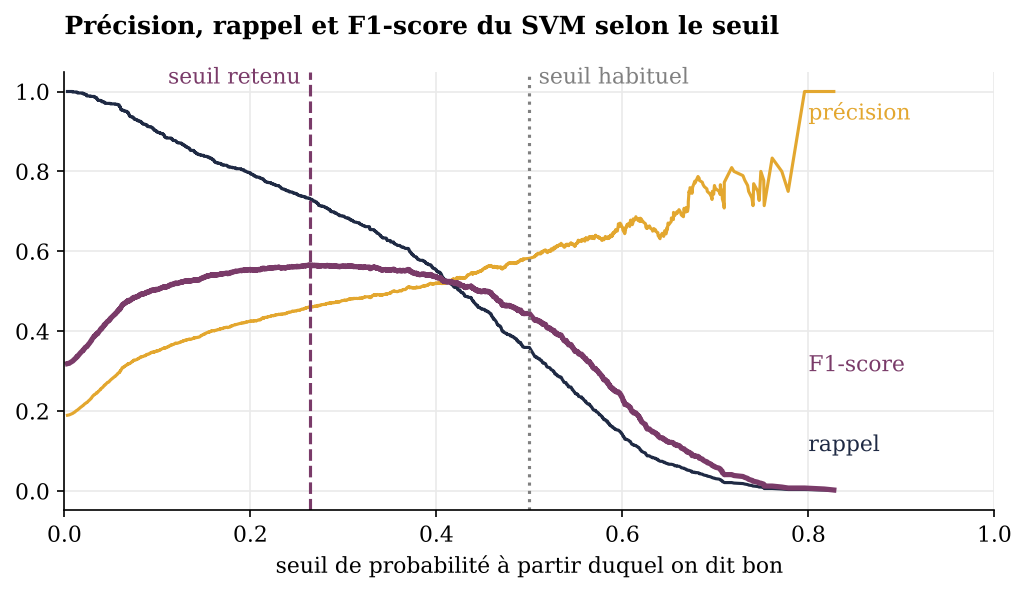

In [40]:
p = probas_cv[choisi]
precisions, rappels, seuils_possibles = precision_recall_curve(y_train, p)
f1 = 2 * precisions * rappels / (precisions + rappels + 1e-12)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(seuils_possibles, precisions[:-1], color=MIEL); ax.text(0.80, 0.93, "précision", color=MIEL)
ax.plot(seuils_possibles, rappels[:-1], color=ENCRE); ax.text(0.80, 0.10, "rappel", color=ENCRE)
ax.plot(seuils_possibles, f1[:-1], color=PRUNE, linewidth=2.5); ax.text(0.80, 0.30, "F1-score", color=PRUNE)
ax.axvline(0.5, color="gray", linestyle=":"); ax.text(0.51, 1.02, "seuil habituel", color="gray")
ax.axvline(seuils[choisi], color=PRUNE, linestyle="--"); ax.text(seuils[choisi] - 0.01, 1.02, "seuil retenu", color=PRUNE, ha="right")
ax.set_xlabel("seuil de probabilité à partir duquel on dit bon"); ax.set_xlim(0, 1)
ax.set_title(f"Précision, rappel et F1-score du {choisi} selon le seuil", pad=18)
plt.show()

In [41]:
# Ce que donnent quelques seuils, avec les probabilités de validation croisée sur les vins d'entraînement
# Les seuils 0,10 et 0,72 sont ceux des usages présélection et prestige, calculés de la même façon qu'en 3.6
precisions, rappels, seuils_possibles = precision_recall_curve(y_train, probas_cv[choisi])
seuil_large = seuils_possibles[rappels[:-1] >= 0.90].max()
seuil_strict = seuils_possibles[precisions[:-1] >= 0.80].min()

lignes = []
for seuil_essaye in [seuil_large, seuils[choisi], 0.50, seuil_strict]:
    decision = probas_cv[choisi] >= seuil_essaye
    lignes.append({"seuil": round(float(seuil_essaye), 2), "vins annoncés bons": int(decision.sum()),
                   "précision": precision_score(y_train, decision), "rappel": recall_score(y_train, decision),
                   "F1-score": f1_score(y_train, decision)})
pd.DataFrame(lignes).set_index("seuil").round(2)

,vins annoncés bons,précision,rappel,F1-score
seuil,,,,
0.10,2075,0.35,0.90,0.50
0.26,1282,0.46,0.73,0.57
0.50,498,0.58,0.36,0.44
0.72,21,0.81,0.02,0.04


Quand le seuil baisse, le rappel monte et la précision descend. On retrouve plus de bons vins mais on se trompe plus souvent quand on annonce un bon vin. Le tableau donne les valeurs pour quatre seuils.

Au seuil habituel de 0,5, le modèle n'annonce bons que 498 vins. Sa précision est correcte (58 %) mais il ne retrouve que 36 % des bons vins. Au seuil retenu de 0,26, il annonce 1 282 vins, retrouve 73 % des bons vins et garde une précision de 46 %. C'est le meilleur F1-score (0,57), donc le meilleur équilibre entre les deux erreurs. Au seuil de 0,10, il retrouve 90 % des bons vins, mais seulement 35 % des vins annoncés bons le sont vraiment. Au seuil de 0,72, 81 % des vins annoncés bons le sont vraiment, mais il n'en annonce que 21 et ne retrouve que 2 % des bons vins.

Aucun seuil n'est donc bon dans l'absolu, chacun correspond à un besoin. Le seuil de 0,26 convient quand les deux erreurs sont aussi graves, celui de 0,10 sert à ne rater presque aucun bon vin et celui de 0,72 à ne garder que des vins très sûrs.

Sur la courbe, le F1-score est assez plat entre 0,2 et 0,4, le choix exact du seuil compte donc peu dans cette zone. À droite de 0,7 la précision devient très irrégulière car très peu de vins ont une probabilité aussi haute.

## 3.3 Que vaut-il sur des vins qu'il n'a jamais vus ?

Tous les choix sont faits, nous ouvrons donc le jeu de test une seule fois. Chaque modèle est évalué avec le seuil fixé en 3.2. Nous ajoutons un modèle qui répond toujours mauvais pour avoir un point de comparaison.

Comme le test ne contient qu'un millier de vins, l'AUC mesurée dépend un peu des vins qui s'y trouvent. Pour savoir à quel point, nous utilisons le bootstrap. On tire au hasard 1 064 vins parmi ceux du test en acceptant de tirer plusieurs fois le même, puis on recalcule l'AUC. En répétant ce tirage 1 000 fois, on obtient un intervalle qui contient l'AUC 95 fois sur 100.

In [42]:
def mesures(y_vrai, probas, seuil):
    prediction = probas >= seuil
    return {"accuracy": accuracy_score(y_vrai, prediction),
            "précision": precision_score(y_vrai, prediction, zero_division=0),
            "rappel": recall_score(y_vrai, prediction),
            "F1-score": f1_score(y_vrai, prediction),
            "AUC": roc_auc_score(y_vrai, probas)}

def intervalle_auc(y_vrai, probas, tirages=1000):
    """Intervalle à 95 % de l'AUC par bootstrap. On retire au hasard autant de vins du test, avec remise, 1 000 fois."""
    hasard = np.random.default_rng(GRAINE)
    y_vrai = np.asarray(y_vrai)
    aucs = []
    for _ in range(tirages):
        tirage = hasard.integers(0, len(y_vrai), len(y_vrai))
        aucs.append(roc_auc_score(y_vrai[tirage], probas[tirage]))
    bas, haut = np.percentile(aucs, [2.5, 97.5])
    return f"{bas:.3f} à {haut:.3f}"

probas_test = {nom: modele.predict_proba(X_test)[:, 1] for nom, modele in optimises.items()}

lignes = [{"modèle": nom, "seuil": seuils[nom], **mesures(y_test, p, seuils[nom]),
           "intervalle de l'AUC à 95 %": intervalle_auc(y_test, p)} for nom, p in probas_test.items()]
naif = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
lignes.append({"modèle": "Toujours répondre mauvais", "seuil": np.nan, **mesures(y_test, naif.predict_proba(X_test)[:, 1], 0.5),
               "intervalle de l'AUC à 95 %": ""})
resultats = pd.DataFrame(lignes).set_index("modèle").sort_values("AUC", ascending=False)
resultats.round(3)

,seuil,accuracy,précision,rappel,F1-score,AUC,intervalle de l'AUC à 95 %
modèle,,,,,,,
k plus proches voisins,0.290,0.797,0.477,0.703,0.568,0.850,0.822 à 0.876
SVM,0.264,0.785,0.461,0.787,0.581,0.850,0.823 à 0.875
Régression logistique,0.221,0.781,0.455,0.772,0.572,0.846,0.816 à 0.873
Arbre de décision,0.226,0.743,0.403,0.728,0.519,0.811,0.777 à 0.841
Naive Bayes,0.336,0.781,0.447,0.644,0.527,0.810,0.777 à 0.840
Toujours répondre mauvais,NaN,0.810,0.000,0.000,0.000,0.500,


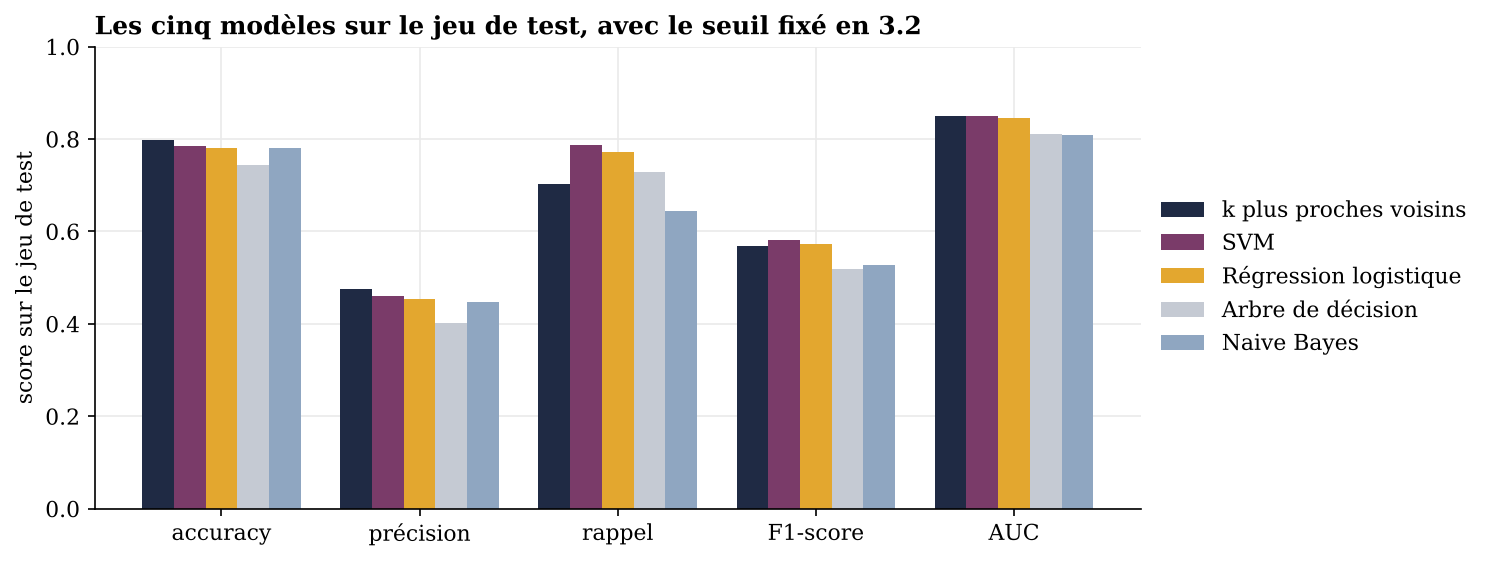

In [43]:
# Comparaison des cinq modèles sur le jeu de test, mesure par mesure
mesures_a_comparer = ["accuracy", "précision", "rappel", "F1-score", "AUC"]
noms_modeles = [nom for nom in resultats.index if nom in optimises]
couleurs = {"SVM": PRUNE, "k plus proches voisins": ENCRE, "Régression logistique": MIEL,
            "Arbre de décision": BRUME, "Naive Bayes": "#8FA6C1"}
largeur = 0.16
fig, ax = plt.subplots(figsize=(9, 4))
for k, nom in enumerate(noms_modeles):
    positions = np.arange(len(mesures_a_comparer)) + (k - 2) * largeur
    ax.bar(positions, resultats.loc[nom, mesures_a_comparer], width=largeur, color=couleurs[nom], label=nom)
ax.set_xticks(range(len(mesures_a_comparer))); ax.set_xticklabels(mesures_a_comparer)
ax.set_ylim(0, 1); ax.set_ylabel("score sur le jeu de test")
ax.set_title("Les cinq modèles sur le jeu de test, avec le seuil fixé en 3.2")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

La dernière ligne confirme ce qui était annoncé en 1.3. Répondre toujours mauvais donne 81 % d'accuracy, plus que tous nos modèles, sans trouver un seul bon vin. C'est pour cela que nous ne jugeons pas les modèles sur l'accuracy.

Sur 100 bons vins, le SVM en retrouve 79. Sur 100 vins qu'il annonce bons, 46 le sont vraiment. En tirant des vins au hasard, on n'en aurait que 19 de bons sur 100. Le modèle fait donc 2,4 fois mieux que le hasard.

L'AUC du SVM se situe entre 0,823 et 0,875. Les intervalles des trois premiers modèles se recouvrent presque entièrement, on ne peut donc pas dire sur le test que l'un est meilleur que les autres. Cela confirme la section 3.1 où le SVM et les voisins étaient déjà très proches. L'arbre et Naive Bayes restent en retrait comme en validation. Enfin l'AUC du SVM sur le test (0,850) est très proche de celle obtenue en validation croisée (0,843). Le score annoncé avant d'ouvrir le test était donc fiable.

Ces mesures complètent l'AUC. L'AUC dit si le modèle range bien les vins, alors que la précision, le rappel et le F1-score jugent ses décisions une fois le seuil fixé, c'est à dire ce qu'obtiendra réellement celui qui utilise le modèle. Le rappel dit combien de bons vins sont retrouvés et la précision si l'on peut faire confiance à un vin annoncé bon. Avec si peu de bons vins, ce sont ces deux mesures qui comptent le plus.

Le graphique reprend ces mesures pour les cinq modèles. Le SVM, les voisins et la régression logistique sont presque à égalité sur chaque mesure. Ce qui les distingue surtout est le partage entre précision et rappel. Les voisins ont la meilleure précision (0,48) mais le rappel le plus faible des trois (0,70), alors que le SVM a le meilleur rappel (0,79). L'arbre et Naive Bayes sont en dessous en F1-score et en AUC. L'accuracy change peu d'un modèle à l'autre et reste sous les 81 % du modèle qui répond toujours mauvais, elle ne sert donc pas à départager les modèles.

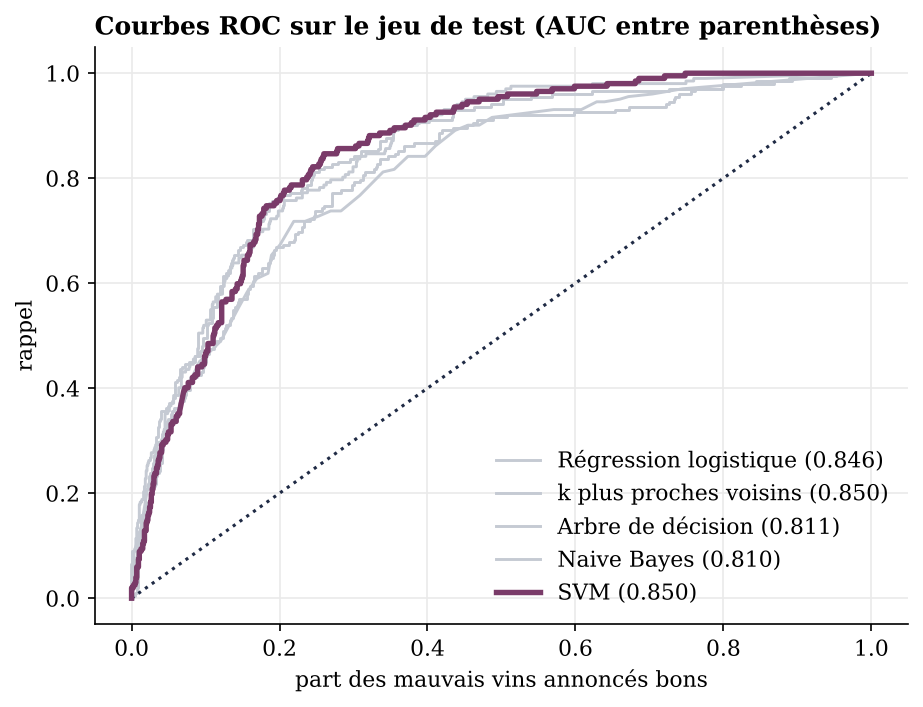

In [44]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom, p in probas_test.items():
    faux_positifs, vrais_positifs, _ = roc_curve(y_test, p)
    retenu = nom == choisi
    ax.plot(faux_positifs, vrais_positifs, color=PRUNE if retenu else BRUME, linewidth=2.6 if retenu else 1.4,
            zorder=3 if retenu else 2, label=f"{nom} ({roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color=ENCRE, linestyle=":")
ax.set_xlabel("part des mauvais vins annoncés bons"); ax.set_ylabel("rappel")
ax.set_title("Courbes ROC sur le jeu de test (AUC entre parenthèses)"); ax.legend(loc="lower right")
plt.show()

Une courbe ROC montre ce que l'on gagne et ce que l'on paie quand on baisse le seuil. En abscisse on lit la part des mauvais vins annoncés bons à tort, et en ordonnée la part des bons vins retrouvés. La diagonale en pointillés correspond à un modèle qui répondrait au hasard, et un modèle parfait passerait par le coin en haut à gauche.

Toutes les courbes sont nettement au dessus de la diagonale. Pour le SVM, si l'on accepte d'annoncer bons 10 % des mauvais vins, on retrouve 47 % des bons vins. Si l'on accepte 20 %, on en retrouve 76 %. Au delà, la courbe s'aplatit et chaque bon vin supplémentaire coûte beaucoup de fausses alertes.

Les courbes du SVM, des voisins et de la régression logistique se croisent plusieurs fois. Aucune n'est au dessus des autres partout, ce qui confirme qu'ils sont équivalents sur le test. Celles de l'arbre et de Naive Bayes sont un peu en dessous sur la plus grande partie du graphique.

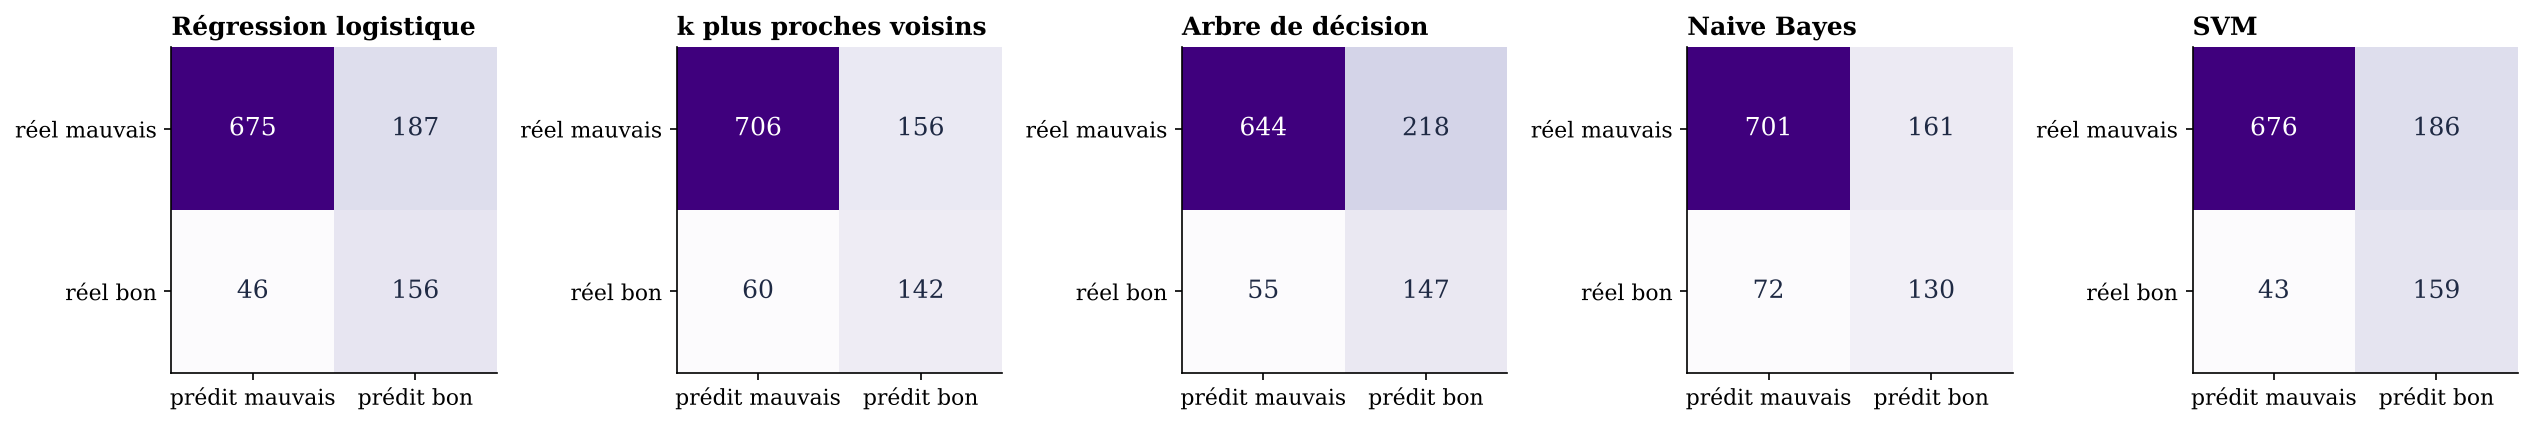

In [45]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, nom in zip(axes, optimises):
    matrice = confusion_matrix(y_test, probas_test[nom] >= seuils[nom])
    ax.imshow(matrice, cmap="Purples"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, matrice[i, j], ha="center", va="center", fontsize=12,
                    color="white" if matrice[i, j] > matrice.max() / 2 else ENCRE)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["prédit mauvais", "prédit bon"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["réel mauvais", "réel bon"])
    ax.set_title(nom)
plt.tight_layout(); plt.show()

Chaque matrice se lit ainsi. En haut à gauche on trouve les mauvais vins bien reconnus, en bas à droite les bons vins retrouvés, en haut à droite les fausses alertes et en bas à gauche les bons vins ratés.

Les cinq matrices ont la même forme. Tous les modèles font plus de fausses alertes que de bons vins ratés, par exemple 186 contre 43 pour le SVM. C'est la conséquence des seuils bas choisis en 3.2. Nous acceptons d'annoncer trop de bons vins pour en rater moins.

La comparaison entre le SVM et les voisins illustre bien le compromis entre précision et rappel. Les voisins font moins de fausses alertes (156 contre 186) mais ratent plus de bons vins (60 contre 43). Pour une AUC égale, le SVM retrouve donc plus de bons vins, tandis que les voisins se trompent un peu moins souvent quand ils annoncent un bon vin.

## 3.4 Est-il aussi bon sur les rouges que sur les blancs ?

Comme la séparation de la section 1.4 respectait la part de rouges, nous pouvons évaluer le modèle séparément sur chaque couleur.

In [46]:
lignes = []
for couleur in ["rouge", "blanc"]:
    masque = (test["type"] == couleur).values
    lignes.append({"couleur": couleur, "vins": masque.sum(), "bons vins": y_test[masque].sum(),
                   **mesures(y_test[masque], probas_test[choisi][masque], seuils[choisi])})
par_couleur = pd.DataFrame(lignes).set_index("couleur")
par_couleur.round(3)

,vins,bons vins,accuracy,précision,rappel,F1-score,AUC
couleur,,,,,,,
rouge,272,37,0.864,0.500,0.73,0.593,0.882
blanc,792,165,0.758,0.454,0.80,0.579,0.836


L'AUC est de 0,882 sur les rouges et de 0,836 sur les blancs, le modèle semble donc un peu meilleur sur les rouges. Il faut rester prudent car le test ne contient que 37 bons vins rouges. Il s'agit d'une tendance et pas d'une certitude.

## 3.5 Où se trompe-t-il, et pourquoi ?

Le modèle n'a jamais vu la note sur 10, seulement la cible bon ou pas bon. Nous regardons pourtant ses réponses note par note pour voir où se trouvent ses erreurs.

186 faux positifs, dont 84% sont des vins notés 6
43 faux négatifs, dont 93% sont des vins notés 7


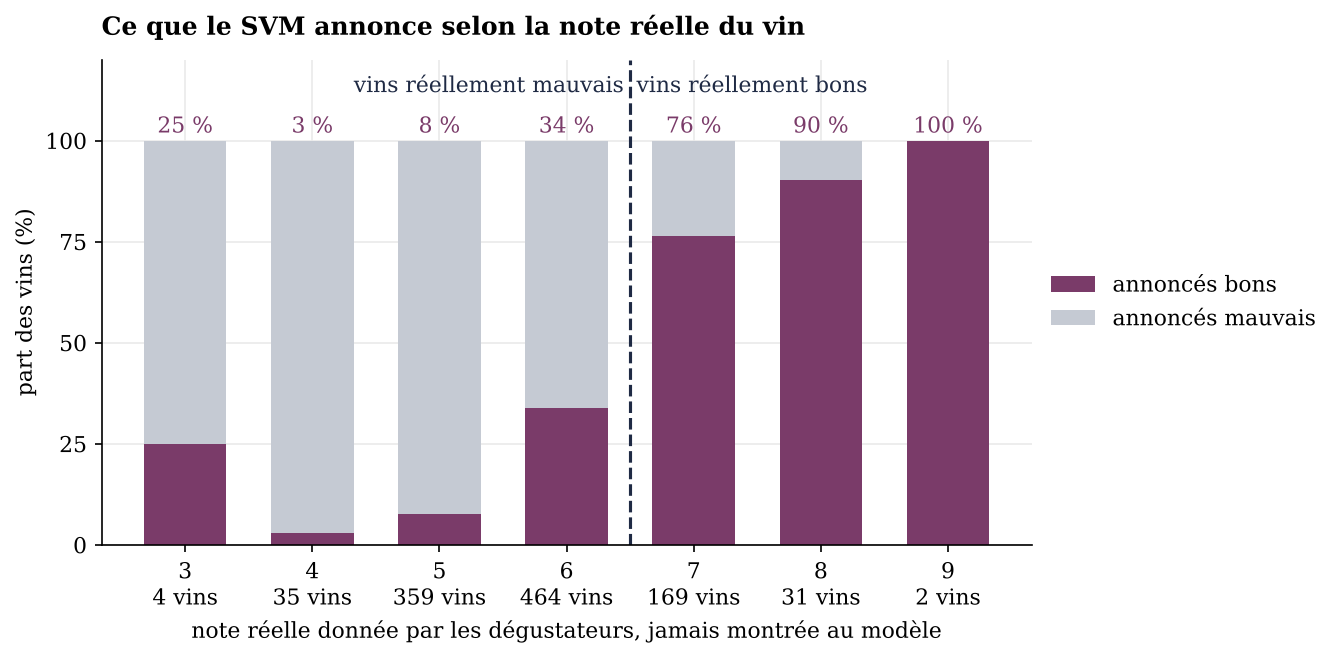

,vins,probabilite_mediane,part_predite_bonne,part d'erreurs
note,,,,
3,4,0.051,0.250,0.250
4,35,0.028,0.029,0.029
5,359,0.038,0.075,0.075
6,464,0.125,0.338,0.338
7,169,0.432,0.763,0.237
8,31,0.465,0.903,0.097
9,2,0.493,1.000,0.000


In [47]:
analyse = pd.DataFrame({"note": test["quality"].values, "probabilité": probas_test[choisi],
                        "prédit bon": probas_test[choisi] >= seuils[choisi]})
par_note = analyse.groupby("note").agg(vins=("note", "size"), probabilite_mediane=("probabilité", "median"),
                                       part_predite_bonne=("prédit bon", "mean"))
par_note["part d'erreurs"] = np.where(par_note.index >= 7, 1 - par_note["part_predite_bonne"], par_note["part_predite_bonne"])

# Pour chaque note réelle, part des vins annoncés bons (violet) et annoncés mauvais (gris)
notes_vues = list(par_note.index)
annonces_bons = par_note["part_predite_bonne"] * 100
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(notes_vues, annonces_bons, width=0.65, color=PRUNE, label="annoncés bons")
ax.bar(notes_vues, 100 - annonces_bons, bottom=annonces_bons, width=0.65, color=BRUME, label="annoncés mauvais")
for n in notes_vues:
    ax.text(n, 102, f"{annonces_bons[n]:.0f} %", ha="center", color=PRUNE)
ax.axvline(6.5, color=ENCRE, linestyle="--")
ax.text(6.45, 112, "vins réellement mauvais", ha="right", color=ENCRE)
ax.text(6.55, 112, "vins réellement bons", ha="left", color=ENCRE)
ax.set_ylim(0, 120); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xticks(notes_vues); ax.set_xticklabels([f"{n}\n{c} vins" for n, c in zip(notes_vues, par_note["vins"])])
ax.set_xlabel("note réelle donnée par les dégustateurs, jamais montrée au modèle")
ax.set_ylabel("part des vins (%)")
ax.set_title("Ce que le SVM annonce selon la note réelle du vin", pad=12)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

faux_positifs = analyse[(analyse["note"] < 7) & analyse["prédit bon"]]
faux_negatifs = analyse[(analyse["note"] >= 7) & ~analyse["prédit bon"]]
print(f"{len(faux_positifs)} faux positifs, dont {(faux_positifs['note'] == 6).mean():.0%} sont des vins notés 6")
print(f"{len(faux_negatifs)} faux négatifs, dont {(faux_negatifs['note'] == 7).mean():.0%} sont des vins notés 7")
par_note.round(3)

Chaque barre regroupe les vins d'une même note réelle. La partie violette est la part des vins que le modèle annonce bons et la partie grise celle qu'il annonce mauvais. À gauche de la ligne pointillée se trouvent les vins réellement mauvais, pour eux le violet est une erreur. À droite se trouvent les vins réellement bons, pour eux c'est le gris qui est une erreur. Les notes 3 et 9 ne comptent que 4 et 2 vins, on ne peut donc rien en conclure.

Le modèle ne connaît pas la note, pourtant il annonce bons de plus en plus de vins quand elle monte. C'est le cas de 3 % des vins notés 4, 8 % des 5, 34 % des 6, 76 % des 7 et 90 % des 8. Le tableau sous le graphique montre que la probabilité médiane suit la même progression, avec 0,04 pour un 5, 0,12 pour un 6, 0,43 pour un 7 et 0,47 pour un 8. Le modèle a donc bien appris ce qui fait monter la qualité.

Les erreurs se concentrent sur les deux notes qui entourent la frontière. Un tiers des vins notés 6 est annoncé bon à tort, et près d'un quart des vins notés 7 est raté. C'est pourquoi 84 % des fausses alertes sont des vins notés 6 et 93 % des bons vins ratés sont des vins notés 7. Les vins notés 4, 5 ou 8, plus éloignés de la frontière, sont presque toujours bien classés.

Pour comprendre pourquoi cette frontière est difficile, nous cherchons des vins qui se ressemblent beaucoup et qui n'ont pas la même étiquette.

In [48]:
# Pour chaque vin d'entraînement, on cherche le vin le plus ressemblant (distance calculée sur les mesures standardisées)
X_std = StandardScaler().fit_transform(X_train)
distances, positions = NearestNeighbors(n_neighbors=2).fit(X_std).kneighbors(X_std)
paires = pd.DataFrame({"vin": range(len(train)), "voisin": positions[:, 1], "distance": distances[:, 1]})
paires["étiquettes différentes"] = train["bon"].values[paires["vin"]] != train["bon"].values[paires["voisin"]]

# Les deux vins les plus ressemblants qui n'ont pas la même étiquette
plus_proche = paires[paires["étiquettes différentes"]].sort_values("distance").iloc[0]
jumeaux = train.iloc[[int(plus_proche["vin"]), int(plus_proche["voisin"])]][["type"] + variables[:-1] + ["quality"]]
jumeaux.index = ["vin A", "vin B"]

# Point de comparaison, deux vins pris au hasard ont des étiquettes différentes dans 2 x p x (1 - p) des cas
part_bons = y_train.mean()
presque_identiques = paires[paires["distance"] < 0.5]
print(f"Deux vins pris au hasard ont des étiquettes différentes dans {2 * part_bons * (1 - part_bons):.0%} des cas.")
print(f"Un vin et son voisin le plus ressemblant ont des étiquettes différentes dans {paires['étiquettes différentes'].mean():.0%} des cas.")
print(f"{len(presque_identiques)} vins ont un voisin presque identique (distance inférieure à 0,5), "
      f"et l'étiquette diffère pour {presque_identiques['étiquettes différentes'].sum()} d'entre eux, soit {presque_identiques['étiquettes différentes'].mean():.0%}.")
jumeaux.T

Deux vins pris au hasard ont des étiquettes différentes dans 31% des cas.
Un vin et son voisin le plus ressemblant ont des étiquettes différentes dans 19% des cas.
590 vins ont un voisin presque identique (distance inférieure à 0,5), et l'étiquette diffère pour 39 d'entre eux, soit 7%.


,vin A,vin B
type,blanc,blanc
fixed acidity,6.4,6.4
volatile acidity,0.17,0.17
citric acid,0.34,0.34
residual sugar,1.5,1.5
chlorides,0.093,0.091
free sulfur dioxide,43.0,42.0
total sulfur dioxide,136.0,135.0
density,0.994,0.994
pH,3.25,3.25


Les deux vins du tableau ont des mesures presque identiques, pourtant l'un a reçu 6 et l'autre 7. Aucun modèle ne peut les séparer à partir de la chimie.

Pour savoir si ce cas est fréquent, il faut un point de comparaison. Deux vins pris au hasard ont des étiquettes différentes dans 31 % des cas. Un vin et son voisin le plus ressemblant n'en ont des différentes que dans 19 % des cas, et ce chiffre tombe à 7 % pour les vins qui ont un voisin presque identique. Plus deux vins se ressemblent, plus ils ont la même étiquette. La composition explique donc bien une grande partie de la qualité, ce qui confirme l'idée de ressemblance de la section 3.1. Mais elle ne l'explique pas entièrement.

La note est donnée par des dégustateurs, et entre un 6 et un 7 l'avis d'une seule personne peut suffire à changer l'étiquette. Une partie des erreurs vient donc de la note elle-même, et aucun modèle ne pourra la corriger.

## 3.6 Quel seuil pour quel usage ?

Le bon seuil dépend de l'erreur qui coûte le plus cher à celui qui utilise le modèle. Monter le seuil limite les faux positifs, c'est à dire les mauvais vins annoncés bons, mais fait rater plus de bons vins. Baisser le seuil limite au contraire les faux négatifs, les bons vins ratés, mais donne plus de fausses alertes. Par exemple, un caviste qui prépare une dégustation baissera le seuil pour ne laisser passer aucun bon vin, quitte à goûter quelques vins moyens en plus. À l'inverse, un concours qui décerne un label montera le seuil pour ne jamais récompenser un vin moyen, quitte à oublier quelques bons vins. Le seuil de 3.2 convient si rater un bon vin et annoncer à tort un bon vin sont aussi graves l'un que l'autre. Pour deux autres usages, nous partons d'un objectif et nous calculons le seuil qui l'atteint sur les vins d'entraînement. Nous vérifions ensuite sur le test.

In [49]:
# Les seuils des deux autres usages sont calculés sur les vins d'entraînement, à partir d'un objectif
precisions, rappels, seuils_possibles = precision_recall_curve(y_train, probas_cv[choisi])
seuil_large = seuils_possibles[rappels[:-1] >= 0.90].max()        # le seuil le plus haut qui retrouve encore 90 % des bons vins
seuil_strict = seuils_possibles[precisions[:-1] >= 0.80].min()    # le seuil le plus bas qui atteint 80 % de précision

usages = {"Présélection (retrouver 90 % des bons vins)": seuil_large,
          "Équilibre (meilleur F1-score)": seuils[choisi],
          "Prestige (80 % de précision)": seuil_strict}
lignes = []
for usage, seuil in usages.items():
    sur_train, sur_test = probas_cv[choisi] >= seuil, probas_test[choisi] >= seuil
    lignes.append({"usage": usage, "seuil": round(seuil, 2),
                   "précision entraînement": precision_score(y_train, sur_train),
                   "rappel entraînement": recall_score(y_train, sur_train),
                   "vins retenus sur le test": sur_test.sum(),
                   "précision test": precision_score(y_test, sur_test, zero_division=0),
                   "rappel test": recall_score(y_test, sur_test),
                   "F1 test": f1_score(y_test, sur_test)})
tableau_usages = pd.DataFrame(lignes).set_index("usage")
large, strict = tableau_usages.iloc[0], tableau_usages.iloc[-1]
print(f"Sur les vins d'entraînement, seuls {(probas_cv[choisi] >= seuil_strict).sum()} vins dépassent le seuil prestige de {seuil_strict:.2f}.")
tableau_usages.round(2)

Sur les vins d'entraînement, seuls 21 vins dépassent le seuil prestige de 0.72.


,seuil,précision entraînement,rappel entraînement,vins retenus sur le test,précision test,rappel test,F1 test
usage,,,,,,,
Présélection (retrouver 90 % des bons vins),0.10,0.35,0.90,523,0.35,0.91,0.51
Équilibre (meilleur F1-score),0.26,0.46,0.73,345,0.46,0.79,0.58
Prestige (80 % de précision),0.72,0.81,0.02,6,0.67,0.02,0.04


Pour une présélection avant dégustation, l'erreur grave est de rater un bon vin. L'objectif est de retrouver au moins 90 % des bons vins, ce qui donne un seuil de 0,10. Sur le test, le modèle retrouve 91 % des bons vins en ne retenant que 523 vins sur 1 064. Les dégustateurs n'ont donc plus à goûter qu'environ la moitié des vins tout en gardant presque tous les bons.

Pour un label prestige, l'erreur grave est au contraire d'annoncer bon un vin qui ne l'est pas. L'objectif est une précision d'au moins 80 %, ce qui donne un seuil de 0,72. Sur le test, seuls 6 vins dépassent ce seuil et 4 sont bons, soit 67 % de précision. L'objectif n'est pas tenu, et c'était prévisible. Même sur les vins d'entraînement, seuls 21 vins dépassaient 0,72, le seuil a donc été fixé sur très peu de cas. Le modèle donne d'ailleurs très rarement des probabilités aussi hautes, seuls 5 % des vins du test dépassent 0,6 et aucun n'atteint 0,8. Notre modèle est donc utile pour faire un premier tri, mais pas pour garantir qu'un vin est excellent.

## 3.7 Quelles sont les limites ?

La principale limite est un plafond d'AUC autour de 0,85. Aucun des cinq modèles ne le dépasse nettement, même après réglage. La section 3.5 en donne une raison, puisqu'une partie des erreurs vient de la note. Nous regardons si plus de vins permettraient d'aller plus loin.

Gain d'AUC de validation entre 2178 et 3404 vins +0.002


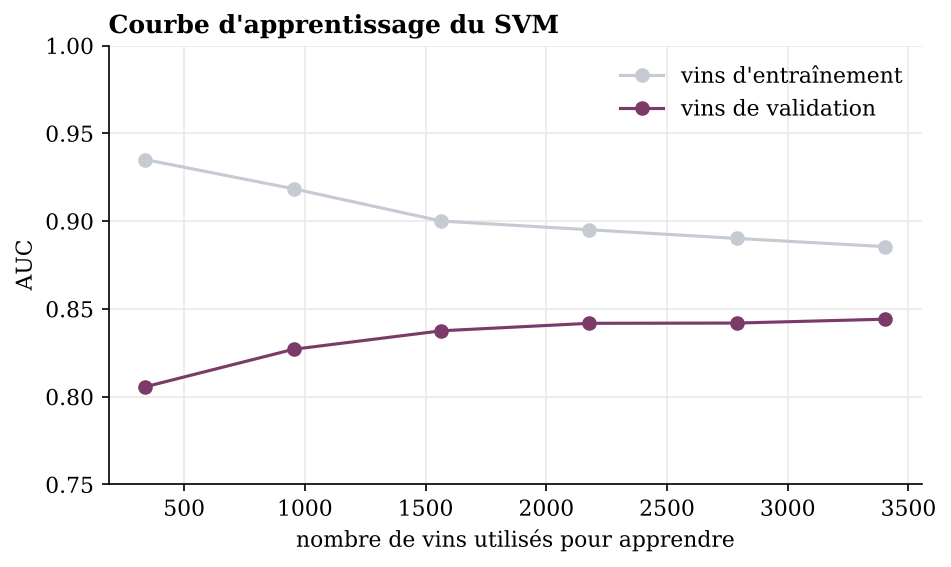

In [50]:
tailles, notes_train, notes_val = learning_curve(a_comparer[choisi], X_train, y_train, cv=cv, scoring="roc_auc",
                                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tailles, notes_train.mean(axis=1), marker="o", color=BRUME, label="vins d'entraînement")
ax.plot(tailles, notes_val.mean(axis=1), marker="o", color=PRUNE, label="vins de validation")
ax.set_ylim(0.75, 1.0); ax.set_xlabel("nombre de vins utilisés pour apprendre"); ax.set_ylabel("AUC")
ax.set_title(f"Courbe d'apprentissage du {choisi}"); ax.legend()
plt.show()
gain_fin = notes_val.mean(axis=1)[-1] - notes_val.mean(axis=1)[-3]
print(f"Gain d'AUC de validation entre {tailles[-3]} et {tailles[-1]} vins {gain_fin:+.3f}")

La courbe d'apprentissage montre le score du modèle selon le nombre de vins utilisés pour apprendre. Le score de validation monte vite au début puis ne progresse presque plus. Entre 2 178 et 3 404 vins, il ne gagne que 0,002 d'AUC. Collecter davantage de vins du même type n'apporterait donc presque rien à ce modèle.

Les deux courbes se rapprochent mais restent séparées d'environ 0,04, avec 0,885 en entraînement contre 0,844 en validation. Le SVM colle donc encore un peu aux vins d'entraînement. Cet écart reste modéré et c'est le prix de la meilleure validation obtenue en 2.6.

D'autres limites viennent des données elles-mêmes. Tous les vins sont des vinhos verdes portugais, rien ne garantit donc que le modèle fonctionne sur des vins d'une autre région. Les 11 mesures ne décrivent pas non plus tout ce qui fait un vin. Le fichier ne contient ni le cépage, ni la marque, ni le prix, alors que ces informations jouent sûrement sur la note. Le fichier contient aussi peu de bons vins, seulement 19 %, et presque aucun vin noté 3, 8 ou 9. Le modèle dispose donc de peu d'exemples des vins les plus intéressants. La courbe d'apprentissage montre que plus de vins n'aiderait presque pas, mais elle garde toujours la même part de bons vins. Ajouter surtout des bons vins pourrait aider un peu, même si l'option `class_weight="balanced"` compense déjà en partie ce déséquilibre.

Plusieurs pistes permettraient d'aller plus loin. On pourrait prédire la note elle-même puis appliquer la limite de 7, pour que le modèle sache qu'un 6 est plus proche d'un 7 que d'un 3. On pourrait faire noter chaque vin par plus de dégustateurs, ce qui rendrait les étiquettes plus sûres. Enfin il faudrait ajouter des informations qui manquent aujourd'hui, comme le cépage.

## 3.8 Que retenir de tout le projet ?

À partir de 11 mesures de laboratoire et de la couleur, notre modèle repère les bons vins 2,4 fois mieux qu'un tirage au hasard. Il peut aider à trier les vins avant une dégustation, mais il ne peut pas remplacer l'avis des dégustateurs.

| Modèle | AUC test | F1 test | Sa force | Sa faiblesse | La raison liée au vin |
|---|---|---|---|---|---|
| SVM | 0,850 | 0,581 | Meilleure AUC sur 25 découpages | Difficile à expliquer mesure par mesure | Sa frontière courbe tient compte de l'équilibre entre les mesures |
| k plus proches voisins | 0,850 | 0,568 | Presque aussi bon, et il peut montrer les vins ressemblants | Inutilisable sans mise à l'échelle | Deux vins de composition proche ont un goût et une note proches |
| Régression logistique | 0,846 | 0,572 | Stable et lisible | Additionne les mesures sans les combiner | Elle saisit l'alcool mais pas l'équilibre du vin |
| Arbre de décision | 0,811 | 0,519 | Des règles que l'on peut lire | Retient les vins un par un s'il n'est pas limité | Il découpe en tranches une qualité qui évolue progressivement |
| Naive Bayes | 0,810 | 0,527 | Très rapide et stable | Se dégrade quand les mesures se répètent | Les mesures d'un vin sont liées par la chimie |

| Choix | Raison | Chiffre |
|---|---|---|
| Supprimer les doublons | Ils laissaient le modèle reconnaître des vins déjà vus | 18 % des lignes, le F1-score des voisins passait de 0,47 à 0,67 avec eux |
| Séparer en respectant la cible et la couleur | Les bons vins rouges sont rares | 184 dans tout le fichier |
| Garder les valeurs extrêmes | Elles signalent les vins ratés | 12 % de bons vins parmi eux, contre 21 % |
| Standardiser dans un pipeline | Les voisins et le SVM calculent des distances | Les voisins passent de 0,705 à 0,827 |
| Garder les 12 mesures, sauf pour Naive Bayes | Lui seul se dégrade quand les mesures se répètent | Il passe de 0,798 à 0,771 avec les 12 |
| Régler avec l'AUC | Le F1-score par défaut favorise les modèles trop collés aux données | Il aurait choisi 3 voisins |
| Retenir le SVM gaussien | Meilleure AUC moyenne sur 25 découpages | 0,843, devant les voisins sur 17 découpages et le noyau linéaire à 0,824 |
| Baisser le seuil | Les bons vins sont rares, le modèle dépasse rarement 0,5 | 0,26 au lieu de 0,5, rappel de 79 % sur le test |

Le modèle final est enregistré pour l'application web, avec les trois seuils calculés dans cette partie.

In [51]:
os.makedirs("app", exist_ok=True)
joblib.dump({"modele": optimises[choisi], "nom": choisi, "seuil": float(seuils[choisi]), "variables": variables,
             "seuils_usages": {"preselection": float(seuil_large), "prestige": float(seuil_strict)},
             "vins_connus": train[variables + ["quality"]]}, "app/modele_final.joblib")
print("Modèle final enregistré,", choisi, "avec les seuils", round(float(seuil_large), 2), round(float(seuils[choisi]), 2), round(float(seuil_strict), 2))

Modèle final enregistré, SVM avec les seuils 0.1 0.26 0.72
